# ROI_processing

In [3]:
import spatialdata_io
import spatialdata as sd
import troutpy
import scanpy as sc
from spatialdata import SpatialData

import matplotlib.pyplot as plt
from spatialdata.transformations import get_transformation
import matplotlib.patches as patches
import os
import numpy as np
import sys
import seaborn as sns


In [43]:
# Technology 1: Xenium
sdata = sd.read_zarr("/media/sergio/Meninges/troutpy/rois/xenium_msbrain_5k/data_processed_with_scores.zarr")#"/media/sergio/Meninges/troutpy/rois/xenium_mscolon_5k/data_processed_filtered.zarr")
saving_path='/media/sergio/Meninges/troutpy/figures'

# Extrasomatic RNA quantification

In [111]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import os
import warnings
warnings.filterwarnings('ignore')
import scanpy as sc

### ==== TOOL FUNCTIONS ==== ###

def load_and_prepare_data(sdata):
    expr = sdata['table'].to_df()
    sdata['table'].X = sdata['table'].layers['raw'].todense()
    cell_types = sdata['table'].obs['cell_type']

    xrna_count = sdata['xrna_metadata'].var['count']
    contrib_df = sdata['source_score'].to_df()
    contrib_df['gene'] = sdata['source_score'].obs['gene']

    return expr, cell_types, xrna_count, contrib_df


def compute_contributions(contrib_df):
    contrib_matrix = contrib_df.groupby('gene').sum()
    contrib_norm = contrib_matrix  # optionally normalize here
    return contrib_norm


def compute_extracellular_counts(contrib_norm, xrna_count):
    genes_common = contrib_norm.index.intersection(xrna_count.index)
    return contrib_norm.loc[genes_common], xrna_count.loc[genes_common]


def compute_intracellular_counts(expr, cell_types):
    grouped = expr.groupby(cell_types)
    return grouped.sum().T, grouped.mean().T


def align_matrices(extra, intra, intra_mean):
    genes_final = extra.index.intersection(intra.index)
    celltypes_final = extra.columns.intersection(intra.columns)
    return (
        extra.loc[genes_final, celltypes_final],
        intra.loc[genes_final, celltypes_final],
        intra_mean.loc[genes_final, celltypes_final],
    )


def compute_extracellular_proportion(extra, intra):
    total = extra + intra
    return extra / total


def filter_genes(intra_mean):
    expr_frac = intra_mean.div(intra_mean.sum(axis=1), axis=0) > 0.1
    expr_level = intra_mean > 0.5
    return expr_frac & expr_level


def collect_filtered_data(extra_matrix, intra_matrix, intra_mean, prop_matrix, combined_filter):
    filtered = []
    for cell_type in extra_matrix.columns:
        extra = extra_matrix[cell_type]
        intra_mean_col = intra_mean[cell_type]
        filt = combined_filter[cell_type]
        prop = prop_matrix[cell_type]

        extra = extra[filt]
        intra_mean_col = intra_mean_col[filt]
        prop = prop[filt].fillna(0)

        for gene in extra.index:
            filtered.append({
                'gene': gene,
                'cell_type': cell_type,
                'extracellular_proportion': prop[gene]
            })
    return pd.DataFrame(filtered)

def compute_and_extrasomatic_proportion(
    sdata,
    source_score_key='source_score',
    expr_key='table',
    xrna_key='xrna_metadata',
    layer_key='raw',
    output_key='extrasomatic_proportion_x_cell_type'
):
    """
    Computes and stores extrasomatic (extracellular) proportion per gene per cell type into `sdata`.

    Parameters
    ----------
    sdata : MuData or dict-like
        Input data object containing 'table', 'source_score', and 'xrna_metadata'.
    source_score_key : str
        Key for accessing source scores (default: 'source_score').
    expr_key : str
        Key for accessing expression table (default: 'table').
    xrna_key : str
        Key for accessing xrna_metadata (default: 'xrna_metadata').
    layer_key : str
        Layer from which to extract raw expression values (default: 'raw').
    output_key : str
        Key where the result `AnnData` object will be stored in `sdata`.

    Returns
    -------
    sdata : updated with `AnnData` object stored at `sdata[output_key]`.
    """

    # 1. Load data
    expr = sdata[expr_key].to_df()
    sdata[expr_key].X = sdata[expr_key].layers[layer_key].todense()
    cell_types = sdata[expr_key].obs['cell_type']

    xrna_count = sdata[xrna_key].var['count']
    contrib_df = sdata[source_score_key].to_df()
    contrib_df['gene'] = sdata[source_score_key].obs['gene']

    # 2. Compute contributions
    contrib_matrix = contrib_df.groupby('gene').sum()
    contrib_norm = contrib_matrix  # optional: normalize here if needed

    # 3. Compute extracellular counts
    genes_common = contrib_norm.index.intersection(xrna_count.index)
    extra_matrix = contrib_norm.loc[genes_common]
    xrna_count = xrna_count.loc[genes_common]

    # 4. Compute intracellular counts
    grouped = expr.groupby(cell_types)
    intra_matrix = grouped.sum().T
    intra_mean_matrix = grouped.mean().T

    # 5. Align all matrices
    genes_final = extra_matrix.index.intersection(intra_matrix.index)
    celltypes_final = extra_matrix.columns.intersection(intra_matrix.columns)

    extra_matrix = extra_matrix.loc[genes_final, celltypes_final]
    intra_matrix = intra_matrix.loc[genes_final, celltypes_final]
    intra_mean_matrix = intra_mean_matrix.loc[genes_final, celltypes_final]

    # 6. Compute extracellular proportion
    extracellular_proportion = extra_matrix / (extra_matrix + intra_matrix)

    # 7. Save result to AnnData
    extrasomatic_ct = sc.AnnData(extracellular_proportion.transpose())
    extrasomatic_ct.obs['cell_type'] = extrasomatic_ct.obs.index
    extrasomatic_ct.layers['extra_expression'] = extra_matrix.transpose()
    extrasomatic_ct.layers['intra_expression'] = intra_matrix.transpose()
    extrasomatic_ct.layers['intra_mean_expression'] = intra_mean_matrix.transpose()

    # 8. Store in sdata
    sdata[output_key] = extrasomatic_ct

    return sdata


### PLOTTING
import os
import matplotlib.pyplot as plt
import pandas as pd

def plot_extrasomatic_scatter_per_celltype(
    sdata,
    extrasomatic_key='extrasomatic_proportion_x_cell_type',
    min_expr_mean=0.5,
    min_expr_frac=0.1,
    figsize=(8, 6),
    s=10,
    color='magenta',
    fontsize=10,
    log_x=True,
    saving_path=None,
    save=False
):
    """
    Plots scatter plots per cell type for extracellular proportion vs intracellular expression.
    All data is extracted from `sdata` under the provided `extrasomatic_key`.

    Parameters
    ----------
    sdata : MuData
        Main data container.
    extrasomatic_key : str
        Key to access extrasomatic data (an AnnData) in sdata.
    min_expr_mean : float
        Minimum average intracellular expression to include gene.
    min_expr_frac : float
        Minimum expression fraction (relative) to include gene.
    figsize : tuple
        Figure size.
    s : float
        Size of the scatter plot points.
    color : str
        Color of scatter plot points.
    fontsize : int
        Font size for gene labels.
    log_x : bool
        Whether to apply log scale to x-axis.
    saving_path : str or None
        Path to save figures if `save` is True.
    save : bool
        Whether to save each plot as PDF.
    """

    extrasomatic = sdata[extrasomatic_key]

    # Ensure all matrices are DataFrames with proper labels
    extra_matrix = pd.DataFrame(
        extrasomatic.layers['extra_expression'].T,
        index=extrasomatic.var_names,
        columns=extrasomatic.obs_names
    )

    intra_matrix = pd.DataFrame(
        extrasomatic.layers['intra_expression'].T,
        index=extrasomatic.var_names,
        columns=extrasomatic.obs_names
    )

    intra_mean_matrix = pd.DataFrame(
        extrasomatic.layers['intra_mean_expression'].T,
        index=extrasomatic.var_names,
        columns=extrasomatic.obs_names
    )

    extracellular_proportion = pd.DataFrame(
        extrasomatic.X.T,
        index=extrasomatic.var_names,
        columns=extrasomatic.obs_names
    )

    # Gene filtering
    gene_filter = (
        (intra_mean_matrix > min_expr_mean) &
        (intra_mean_matrix.div(intra_mean_matrix.sum(axis=1), axis=0) > min_expr_frac)
    )

    for cell_type in extra_matrix.columns:
        extra = extra_matrix[cell_type]
        intra_mean_col = intra_mean_matrix[cell_type]
        prop = extracellular_proportion[cell_type]
        filt = gene_filter[cell_type]

        extra = extra[filt]
        intra_mean_col = intra_mean_col[filt]
        prop = prop[filt].fillna(0)

        plt.figure(figsize=figsize)
        plt.scatter(intra_mean_col, prop, alpha=0.6, s=s, color=color)

        for gene, x, y in zip(extra.index, intra_mean_col, prop):
            plt.text(x, y, gene, fontsize=fontsize, alpha=0.7)

        plt.xlabel("Intracellular Expression")
        plt.ylabel("Extracellular Proportion")
        plt.title(f"Extracellular Enrichment in {cell_type}")
        plt.ylim(-0.05, 1.05)
        plt.grid(True, linestyle='--', alpha=0.5)
        if log_x:
            plt.xscale('log')
        plt.tight_layout()

        if save and saving_path:
            os.makedirs(saving_path, exist_ok=True)
            out_path = os.path.join(saving_path, f"scatter_{cell_type}_extrasomatic.pdf")
            plt.savefig(out_path)

        plt.show()

import os
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import numpy as np
import matplotlib

def plot_violin_of_extrasomatic_proportion(
    sdata,
    extrasomatic_key='extrasomatic_proportion_x_cell_type',
    table_key='table',
    n=1,
    min_expr_mean=0.5,
    min_expr_frac=0.1,
    figsize=(7, 7),s=1,
    saving_path=None,
    save=False
):
    """
    Plot violin + stripplot of extracellular proportions per cell type from `sdata`.

    Parameters
    ----------
    sdata : MuData or dict-like
        Data structure containing the computed extracellular proportions.
    extrasomatic_key : str
        Key where the extrasomatic AnnData is stored in sdata.
    table_key : str
        Key for accessing cell type colors and cell type labels.
    n : int
        Number of top/bottom genes to annotate per cell type.
    min_expr_mean : float
        Minimum average intracellular expression to include gene.
    min_expr_frac : float
        Minimum fraction of expression per cell type to include gene.
    figsize : tuple
        Figure size for the plot.
    saving_path : str or None
        If provided and `save=True`, plot will be saved here.
    s: float
        Size of the dots in the stripplot
    save : bool
        Whether to save the plot to PDF.
    """

    extrasomatic = sdata[extrasomatic_key]

    # Ensure all layers and matrices are DataFrames with proper labels
    extra_matrix = pd.DataFrame(
        extrasomatic.layers['extra_expression'].T,
        index=extrasomatic.var_names,
        columns=extrasomatic.obs_names
    )

    intra_matrix = pd.DataFrame(
        extrasomatic.layers['intra_expression'].T,
        index=extrasomatic.var_names,
        columns=extrasomatic.obs_names
    )

    intra_mean_matrix = pd.DataFrame(
        extrasomatic.layers['intra_mean_expression'].T,
        index=extrasomatic.var_names,
        columns=extrasomatic.obs_names
    )

    extracellular_proportion = pd.DataFrame(
        extrasomatic.X.T,
        index=extrasomatic.var_names,
        columns=extrasomatic.obs_names
    )

    # Apply filters
    gene_filter = (
        (intra_mean_matrix > min_expr_mean) &
        (intra_mean_matrix.div(intra_mean_matrix.sum(axis=1), axis=0) > min_expr_frac)
    )

    filtered_data = []
    for cell_type in extra_matrix.columns:
        extra = extra_matrix[cell_type]
        intra_mean_col = intra_mean_matrix[cell_type]
        prop = extracellular_proportion[cell_type]
        filt = gene_filter[cell_type]

        extra = extra[filt]
        intra_mean_col = intra_mean_col[filt]
        prop = prop[filt].fillna(0)

        for gene in extra.index:
            filtered_data.append({
                'gene': gene,
                'cell_type': cell_type,
                'extracellular_proportion': prop[gene]
            })

    filtered_df = pd.DataFrame(filtered_data)

    # Order cell types by mean extracellular proportion
    order_ct = (
        filtered_df
        .groupby('cell_type')['extracellular_proportion']
        .mean()
        .sort_values(ascending=False)
        .index
    )

    # Use color dictionary from sdata
    coldict = dict(zip(
        np.unique(sdata[table_key].obs['cell_type']),
        sdata[table_key].uns['cell_type_colors']
    ))
    cols = [coldict[c] for c in order_ct]

    # Plot
    # Set font type for vector output
    matplotlib.rcParams['pdf.fonttype'] = 42
    matplotlib.rcParams['ps.fonttype'] = 42
    plt.figure(figsize=figsize, dpi=100)
    ax = sns.violinplot(
        data=filtered_df,
        y='cell_type',
        x='extracellular_proportion',
        order=order_ct,
        alpha=0.8,
        linewidth=0,
        palette=cols,
        inner=None
    )

    sns.stripplot(
        data=filtered_df,
        y='cell_type',
        x='extracellular_proportion',
        color='gray',
        s=s,
        order=order_ct,
        jitter=0.3,
        linewidth=0.01,
        ax=ax
    )

    for cell_type in order_ct:
        df_sub = filtered_df[filtered_df['cell_type'] == cell_type]

        # Top n
        top_n = df_sub.nlargest(n, 'extracellular_proportion')
        for _, row in top_n.iterrows():
            ax.text(row['extracellular_proportion'], cell_type, row['gene'],
                    color='#bf1324', fontsize=10, va='bottom', ha='left')

        # Bottom n
        bottom_n = df_sub.nsmallest(n, 'extracellular_proportion')
        for _, row in bottom_n.iterrows():
            ax.text(row['extracellular_proportion'], cell_type, row['gene'],
                    color='#3d57ad', fontsize=10, va='bottom', ha='right')

    plt.xlabel('Extrasomatic Proportion')
    plt.ylabel('Cell Type')
    plt.tight_layout()

    if save and saving_path:
        os.makedirs(saving_path, exist_ok=True)
        out_path = os.path.join(saving_path, 'cells_extracellular_proportion.pdf')
        plt.savefig(out_path)

    plt.show()


In [87]:
sdata = compute_and_extrasomatic_proportion(sdata)


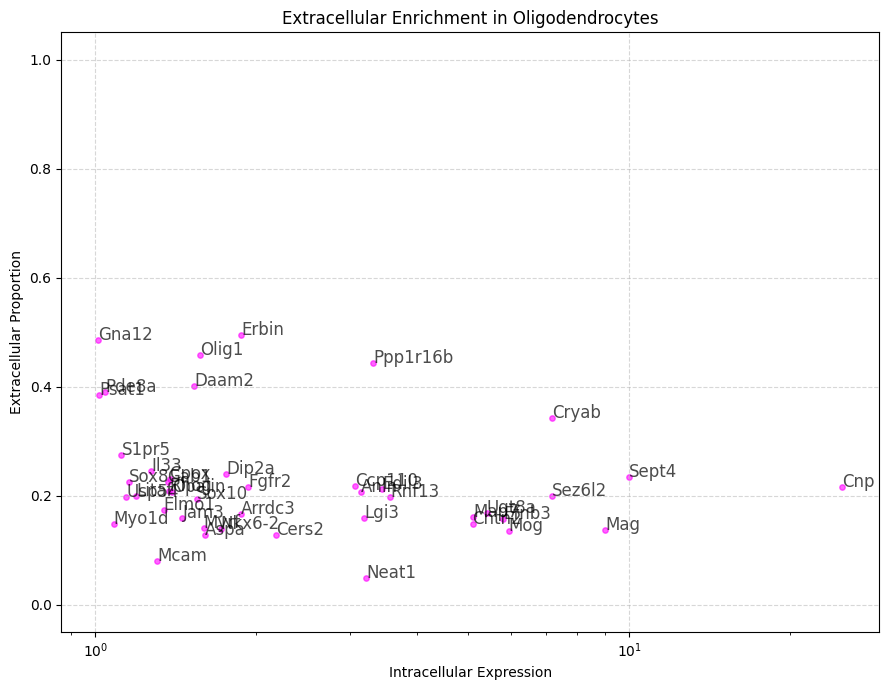

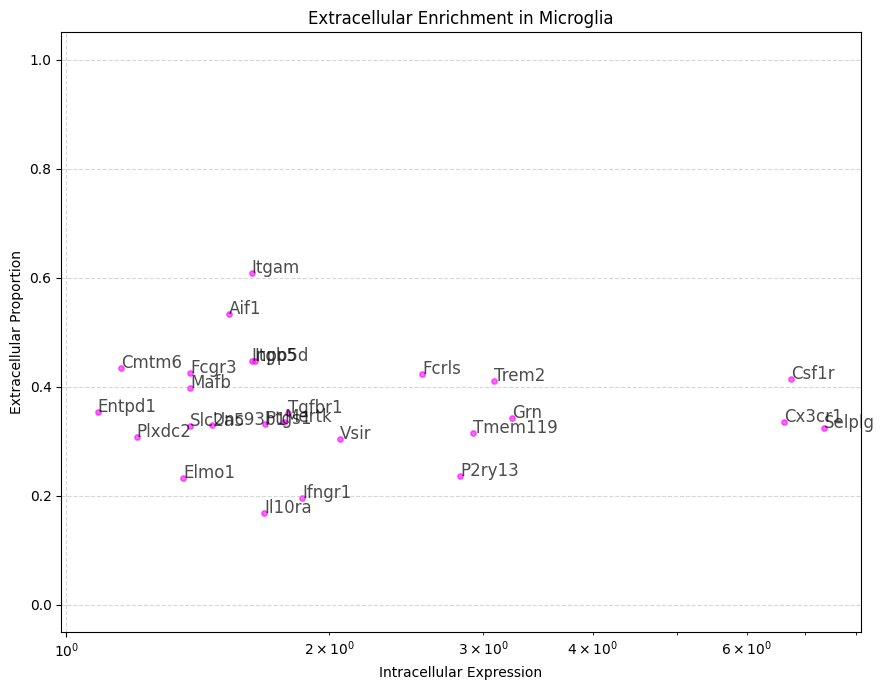

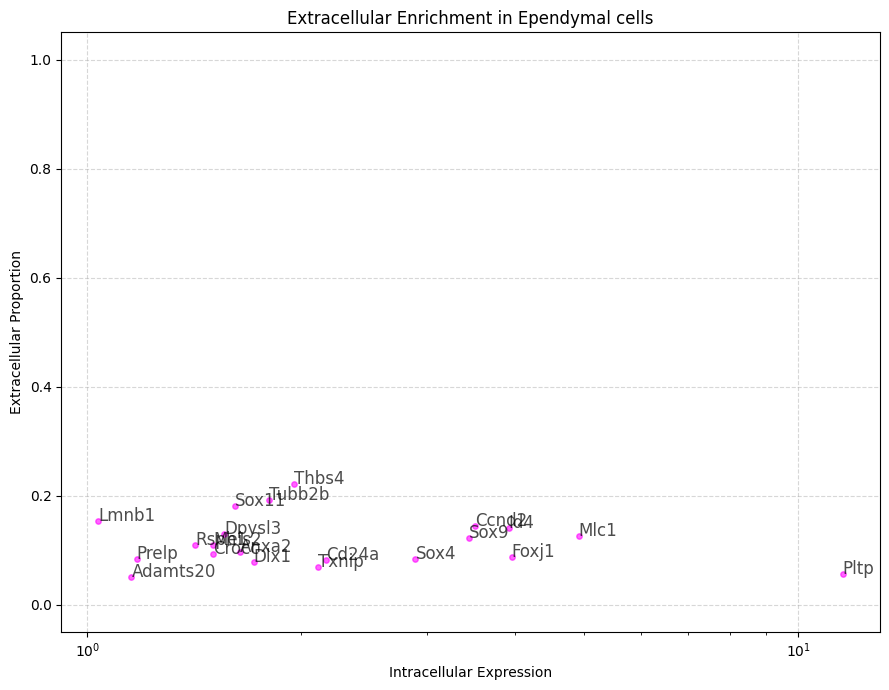

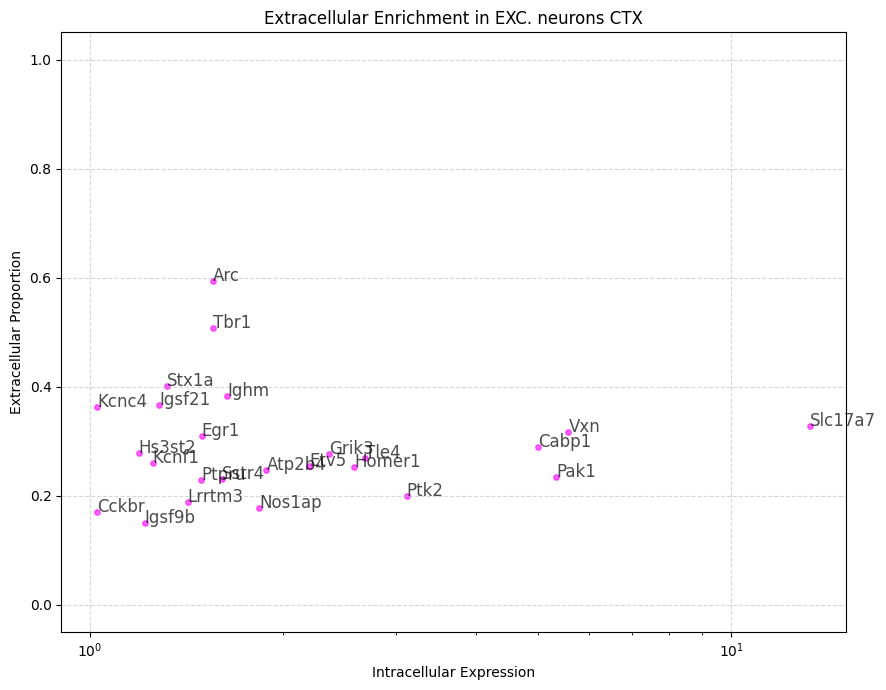

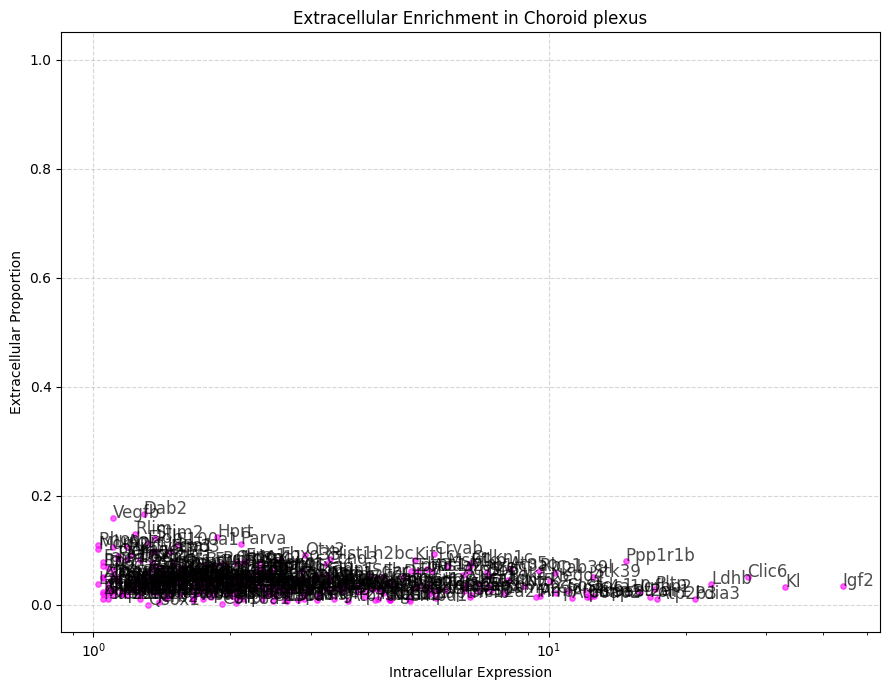

...

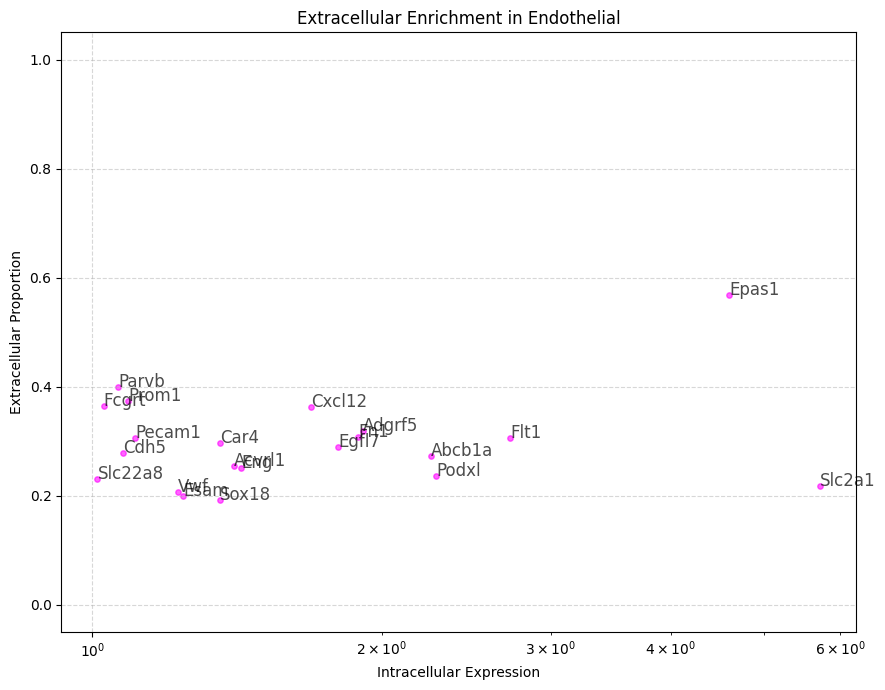

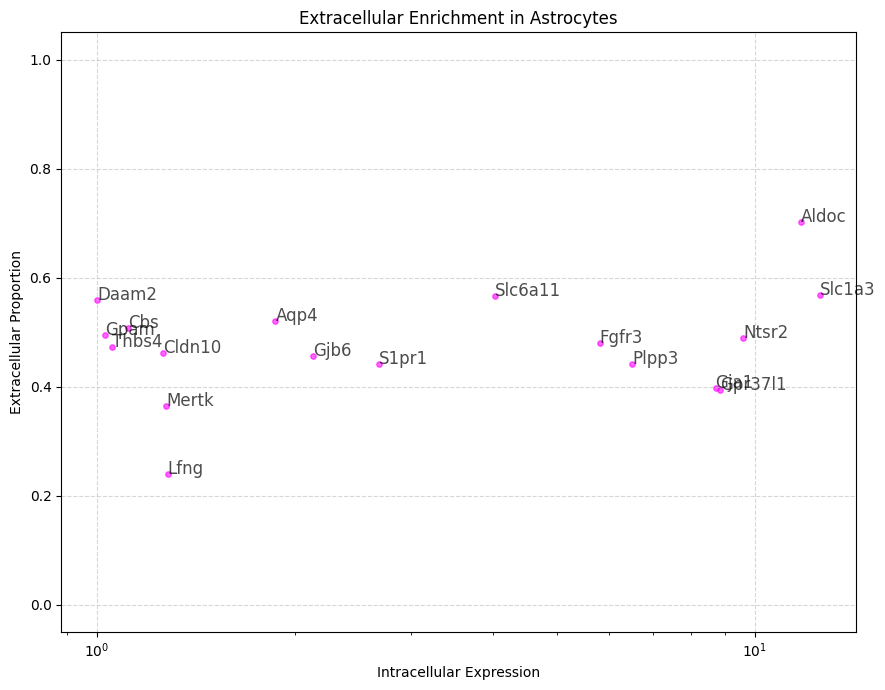

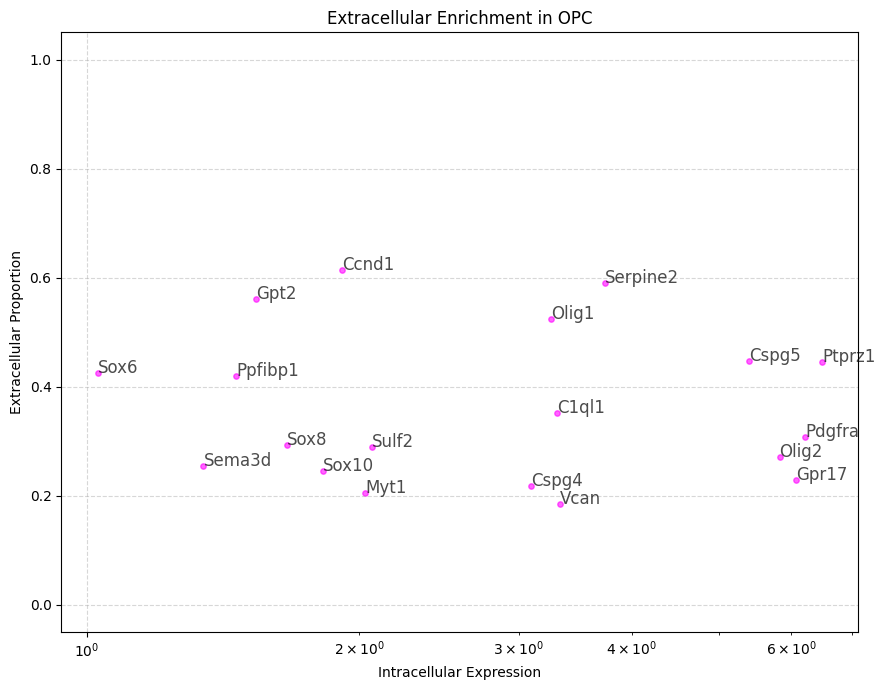

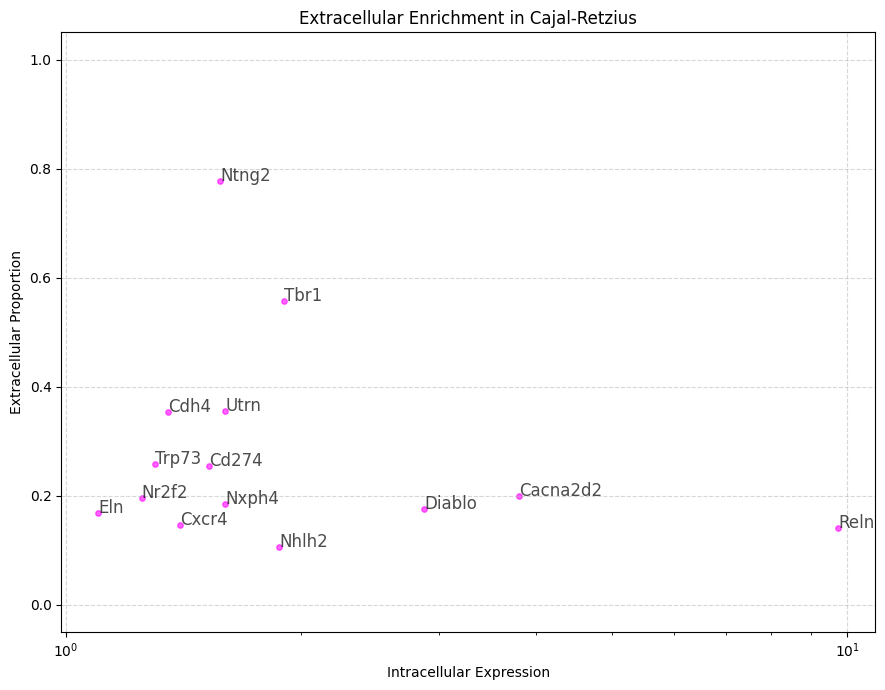

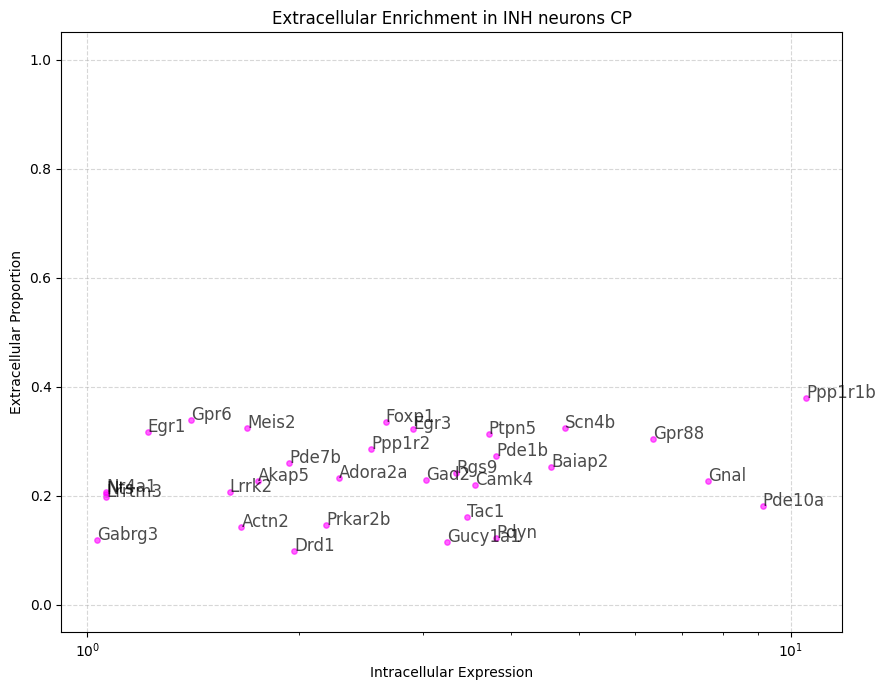

In [109]:
plot_extrasomatic_scatter_per_celltype(sdata,min_expr_mean=1,min_expr_frac=0.2,
    color='magenta',s=15,fontsize=12,figsize=(9, 7),log_x=True,saving_path="results/plots",save=False
)



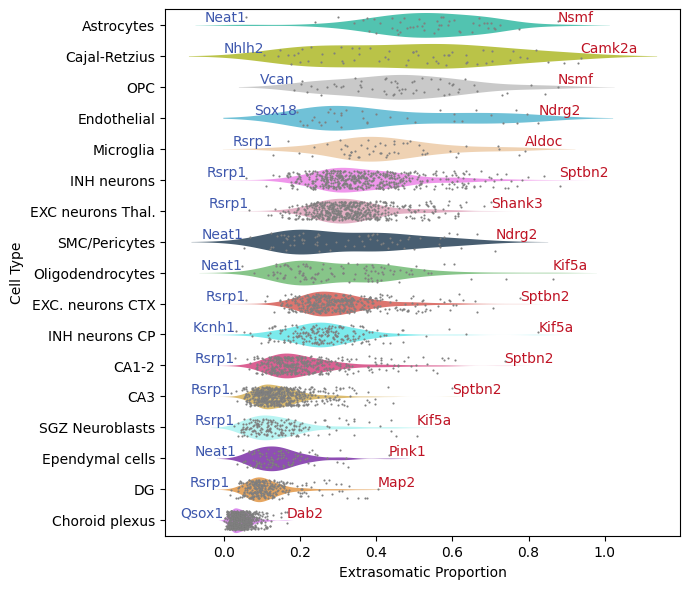

In [113]:
plot_violin_of_extrasomatic_proportion(
    sdata,
    n=1,
    min_expr_mean=1,
    min_expr_frac=0.05, s=1.5,
    figsize=(7, 6),
    saving_path=saving_path,
    save=True
)


No transformation matrix found. Proceeding without transformation.


(<Figure size 1000x1000 with 1 Axes>,
 <Axes: title={'center': 'Cell Boundaries + Transcripts'}>)

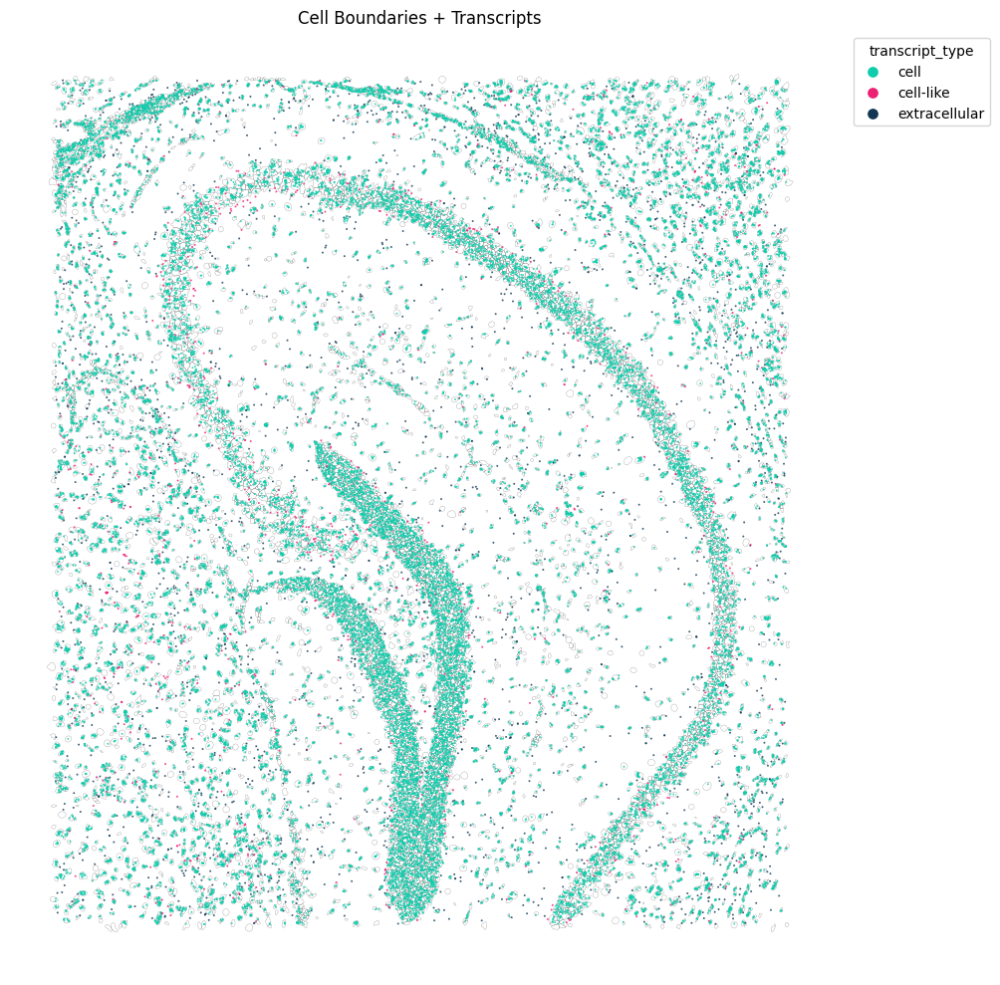

In [121]:
troutpy.pl.spatial_transcripts(sdata,gene_list=['Rsrp1'],scatter_size=2,figsize=(10,10),boundary_linewidth=0.1)

No transformation matrix found. Proceeding without transformation.


(<Figure size 1000x1000 with 1 Axes>,
 <Axes: title={'center': 'Cell Boundaries + Transcripts'}>)

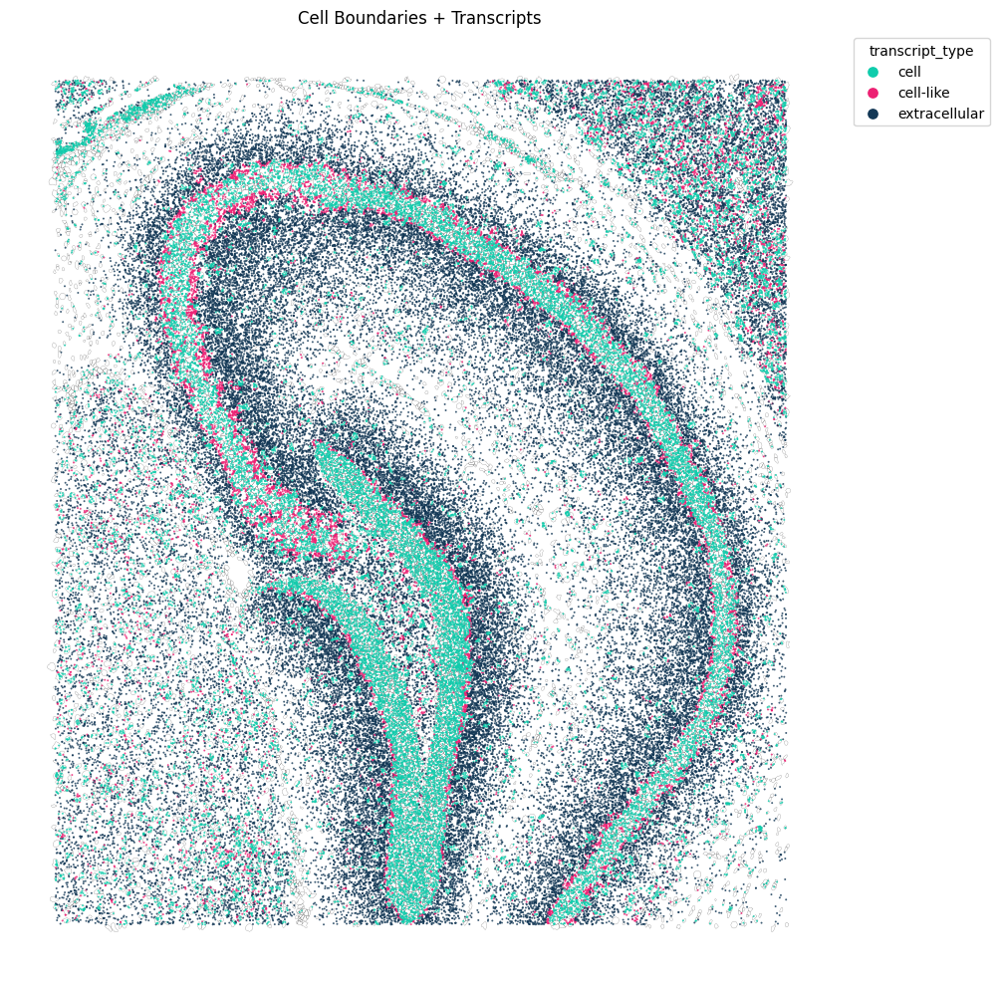

In [120]:
troutpy.pl.spatial_transcripts(sdata,gene_list=['Map2'],scatter_size=2,figsize=(10,10),boundary_linewidth=0.1)

In [171]:
import pandas as pd
import numpy as np
from anndata import AnnData

def identify_unique_expression(
    adata: AnnData,
    threshold: float = 0.2,
    min_mean: float = 1.0
) -> pd.DataFrame:
    """
    Determine for each gene whether it is uniquely expressed in one cell type or multiple,
    based on mean expression per cell type.

    A gene is considered expressed in a cell type if:
    - The mean expression in that cell type contributes more than `threshold`
      of the total mean across all cell types, AND
    - The mean expression is above `min_mean` in that cell type.

    Parameters
    ----------
    adata : AnnData
        AnnData object with expression data in .X and cell type annotations in .obs['cell_type'].
    threshold : float
        Minimum fraction of total mean expression the cell type must contribute to be considered expressed.
    min_mean : float
        Minimum mean expression value in the cell type for a gene to be considered expressed.

    Returns
    -------
    pd.DataFrame
        DataFrame with gene names as index and two columns:
        - 'expression_pattern': 'unique' or 'multiple'
        - 'unique_cell_type': cell type name if uniquely expressed, else None
    """
    cell_types = adata.obs['cell_type'].astype(str)
    gene_names = adata.var_names
    result = []

    # Convert to dense matrix if sparse
    X = adata.X.toarray() if hasattr(adata.X, 'toarray') else adata.X

    # Create map of cell type -> integer indices
    cell_type_groups = cell_types.groupby(cell_types).groups
    cell_indexer = pd.Series(np.arange(adata.n_obs), index=adata.obs.index)

    for gene_idx, gene in enumerate(gene_names):
        mean_expr_by_ct = {}
        for ct, labels in cell_type_groups.items():
            int_indices = cell_indexer.loc[labels].values
            mean_expr_by_ct[ct] = X[int_indices, gene_idx].mean()

        total_mean = sum(mean_expr_by_ct.values())
        if total_mean == 0:
            result.append({'expression_pattern': 'multiple', 'unique_cell_type': None})
            continue

        expressed_in = []
        for ct, mean_expr in mean_expr_by_ct.items():
            frac = mean_expr / total_mean
            if frac >= threshold and mean_expr >= min_mean:
                expressed_in.append(ct)

        if len(expressed_in) == 1:
            result.append({'expression_pattern': 'unique', 'unique_cell_type': expressed_in[0]})
        else:
            result.append({'expression_pattern': 'multiple', 'unique_cell_type': None})

    return pd.DataFrame(result, index=gene_names)


In [296]:
result_table = identify_unique_expression(adata,threshold=0.9, min_mean = 0.5)
unique_expression_genes=result_table[result_table['expression_pattern']!='multiple']
adata_cell_type_specific=adata[:,unique_expression_genes.index]

In [297]:
merged = pd.merge(unique_expression_genes,sdata['xrna_metadata'].var,left_index=True,right_index=True, how='inner')


In [298]:
sdata['table'].uns['cell_type_colors'] = [
    "#0FCCAC",   # Aqua Teal – bright and fresh, great for highlighting
    "#ED2073",   # Vivid Magenta Pink – strong contrast, eye-catching
    "#ebb434", 
    "#BFCE00",   # Chartreuse Green – light, acidic green, good for uncommon categories
    "#DF5AFF",   # Electric Purple – vibrant, stands out, ideal for rare cell types
    "#FC911D",   # Vivid Orange – warm and bold, useful for attention-grabbing
    "#E891B4",   # Pastel Rose – soft and gentle, good for subtle categories
    "#eb3d34",   # Mint Cream – pale green, useful for background or low-contrast layers
    "#37BEE2",   # Bright Sky Blue – vibrant and energetic, visually accessible
    "#790DB7",   # Royal Purple – deep and rich, contrasts well with yellows and greens
    "#ff69f7",   # Lime Green – bold but not neon, works well for active states
    "#43FBFF",   # Neon Cyan – very bright, best with dark backgrounds
    "#F7C894",   # Peach – soft and neutral, ideal for subtle cell states
    "#BCBCBC",   # Medium Gray – neutral, useful as a baseline or control color
    "#5cc460",   # Charcoal – strong neutral, works well for text or background
    "#9CFFFC",
    "#123755",   # Deep Navy Blue – dark and cool, good background or strong category
    "#FFFF7B",   # Soft Lemon Yellow – light and readable on dark backgrounds
]

In [299]:
order_ct=merged.loc[:,['unique_cell_type','extracellular_proportion']].groupby('unique_cell_type').mean().sort_values(by='extracellular_proportion',ascending=False).index

In [300]:
coldict=dict(zip(np.unique(sdata['table'].obs['cell_type']),sdata['table'].uns['cell_type_colors']))
cols=[coldict[c] for c in order_ct]

In [301]:
merged

,expression_pattern,unique_cell_type,count,logfoldratio_over_noise,control_probe,p_value_Poisson,intracellular_proportion,extracellular_proportion,logfoldratio_extracellular,moran_I,moran_pval_norm,moran_var_norm,moran_pval_norm_fdr_bh,in_out_spearmanR,in_out_pvalue,proportion_of_colocalized
Abca4,unique,Choroid plexus,60.0,2.302585,False,0.000000e+00,0.893993,0.106007,1.101746,0.018048,3.088640e-13,0.000006,NaN,-0.001040,9.205842e-01,0.000000
Ace,unique,Choroid plexus,156.0,3.258097,False,0.000000e+00,0.832797,0.167203,0.575138,0.023147,0.000000e+00,0.000006,NaN,0.160829,2.851144e-54,0.026316
Cldn1,unique,Choroid plexus,41.0,1.921813,False,0.000000e+00,0.866013,0.133987,0.835712,-0.001334,3.023508e-01,0.000006,NaN,0.131799,7.158262e-37,0.025000
Cldn2,unique,Choroid plexus,21.0,1.252763,False,0.000000e+00,0.967239,0.032761,2.354751,0.055933,0.000000e+00,0.000006,NaN,0.073431,1.840394e-12,0.050000
Clic3,unique,Choroid plexus,32.0,1.673976,False,0.000000e+00,0.750000,0.250000,0.068166,-0.001047,3.432421e-01,0.000006,NaN,-0.003870,7.107276e-01,0.032258
Clic6,unique,Choroid plexus,169.0,3.338139,False,0.000000e+00,0.906475,0.093525,1.240886,0.279027,0.000000e+00,0.000006,NaN,0.419965,0.000000e+00,0.206349
Cltrn,unique,Choroid plexus,25.0,1.427116,False,0.000000e+00,0.845679,0.154321,0.670659,-0.000781,3.829852e-01,0.000006,NaN,0.022190,3.344801e-02,0.041667
Crhbp,unique,INH neurons,542.0,4.503507,False,0.000000e+00,0.737911,0.262089,0.004693,0.107305,0.000000e+00,0.000006,NaN,0.181200,1.229996e-68,0.195652
Dnah12,unique,Ependymal cells,28.0,1.540445,False,0.000000e+00,0.909677,0.090323,1.279256,-0.000920,3.620525e-01,0.000006,NaN,0.138486,1.452987e-40,0.000000
Ebf3,unique,Cajal-Retzius,24.0,1.386294,False,0.000000e+00,0.856287,0.143713,0.754345,-0.000810,3.785428e-01,0.000006,NaN,0.031131,2.846244e-03,0.000000


In [302]:
merged_labelled.sort_values(by='count')

,expression_pattern,unique_cell_type,count,logfoldratio_over_noise,control_probe,p_value_Poisson,intracellular_proportion,extracellular_proportion,logfoldratio_extracellular,moran_I,moran_pval_norm,moran_var_norm,moran_pval_norm_fdr_bh,in_out_spearmanR,in_out_pvalue,proportion_of_colocalized,gene_name
Slc16a8,unique,Choroid plexus,20.0,1.203973,False,0.0,0.929577,0.070423,1.549771,-0.000551,4.184203e-01,0.000006,NaN,0.155347,1.035666e-50,0.111111,Slc16a8
Cldn2,unique,Choroid plexus,21.0,1.252763,False,0.0,0.967239,0.032761,2.354751,0.055933,0.000000e+00,0.000006,NaN,0.073431,1.840394e-12,0.050000,Cldn2
Mfrp,unique,Choroid plexus,26.0,1.466337,False,0.0,0.958926,0.041074,2.119986,0.006291,5.915065e-03,0.000006,NaN,0.270035,3.232373e-153,0.040000,Mfrp
Clic3,unique,Choroid plexus,32.0,1.673976,False,0.0,0.750000,0.250000,0.068166,-0.001047,3.432421e-01,0.000006,NaN,-0.003870,7.107276e-01,0.032258,Clic3
Nts,unique,INH neurons CP,33.0,1.704748,False,0.0,0.810345,0.189655,0.421806,0.020136,4.440892e-16,0.000006,NaN,0.155700,6.156367e-51,0.000000,Nts
Steap1,unique,Choroid plexus,35.0,1.763589,False,0.0,0.926625,0.073375,1.505516,0.018834,2.975398e-14,0.000006,NaN,0.011373,2.757745e-01,0.000000,Steap1
Cldn1,unique,Choroid plexus,41.0,1.921813,False,0.0,0.866013,0.133987,0.835712,-0.001334,3.023508e-01,0.000006,NaN,0.131799,7.158262e-37,0.025000,Cldn1
Sostdc1,unique,Choroid plexus,42.0,1.945910,False,0.0,0.950237,0.049763,1.918993,0.028202,0.000000e+00,0.000006,NaN,0.247798,1.452486e-128,0.024390,Sostdc1
Folr1,unique,Choroid plexus,51.0,2.140066,False,0.0,0.954626,0.045374,2.015942,0.030410,0.000000e+00,0.000006,NaN,0.318509,1.289186e-215,0.020833,Folr1
Abca4,unique,Choroid plexus,60.0,2.302585,False,0.0,0.893993,0.106007,1.101746,0.018048,3.088640e-13,0.000006,NaN,-0.001040,9.205842e-01,0.000000,Abca4


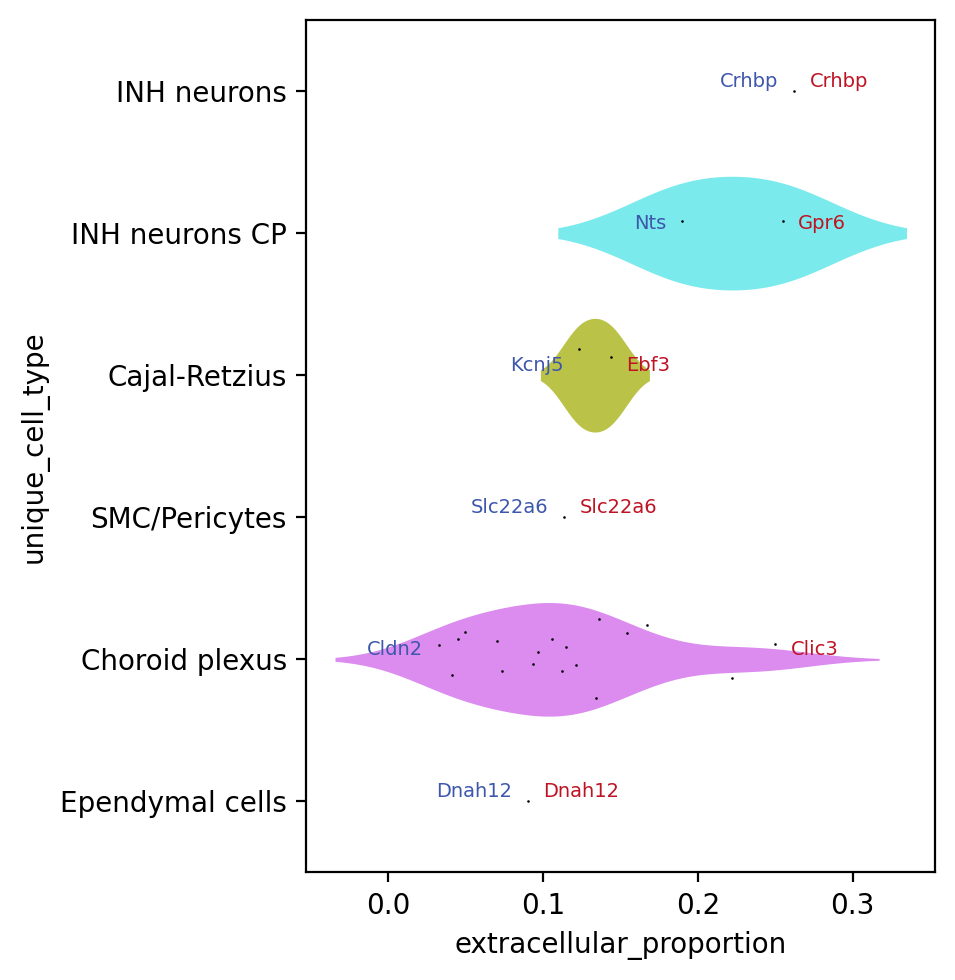

In [303]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

# Parameters
m = 1
n = 1

# Prepare data
merged_labelled = merged.copy()
merged_labelled['gene_name'] = merged_labelled.index

# Create safe order_ct lookup
y_map = {ct: i for i, ct in enumerate(order_ct)}

# Filter to only valid cell types
valid_ct = [ct for ct in merged_labelled['unique_cell_type'].unique() if ct in order_ct]

# Select top and bottom genes
to_label = []
for ct in valid_ct:
    group = merged_labelled[merged_labelled['unique_cell_type'] == ct]
    top_m = group.nlargest(m, 'extracellular_proportion')
    bottom_n = group.nsmallest(n, 'extracellular_proportion')
    to_label.append(pd.concat([top_m, bottom_n]))

label_df = pd.concat(to_label)

# Plot
plt.figure(figsize=(5, 5), dpi=200)

ax =sns.violinplot(
    data=merged_labelled,
    y='unique_cell_type',
    x='extracellular_proportion',
    order=order_ct,
    palette=cols,
    alpha=0.8,linewidth=0,
    inner=None
)

sns.stripplot(
    data=merged_labelled,
    y='unique_cell_type',
    x='extracellular_proportion',
    color='black',
    s=0.7,
    order=order_ct,
    jitter=0.3,
    linewidth=0.2,ax=ax
)

# Annotate top and bottom n genes for each cell type
for cell_type in order_ct:
    df_sub = merged_labelled[merged_labelled['unique_cell_type'] == cell_type]

    # Top n
    top_n = df_sub.nlargest(n, 'extracellular_proportion')
    for _, row in top_n.iterrows():
        ax.text(
            row['extracellular_proportion']+0.01, cell_type,
            row['gene_name'],
            color='#bf1324', fontsize=7, va='bottom', ha='left'
        )

    # Bottom n
    bottom_n = df_sub.nsmallest(n, 'extracellular_proportion')
    for _, row in bottom_n.iterrows():
        ax.text(
            row['extracellular_proportion']-0.01, cell_type,
            row['gene_name'],
            color='#3d57ad', fontsize=7, va='bottom', ha='right'
        )

plt.tight_layout()
plt.show()


No transformation matrix found. Proceeding without transformation.


(<Figure size 800x800 with 1 Axes>,
 <Axes: title={'center': 'Cell Boundaries + Transcripts'}>)

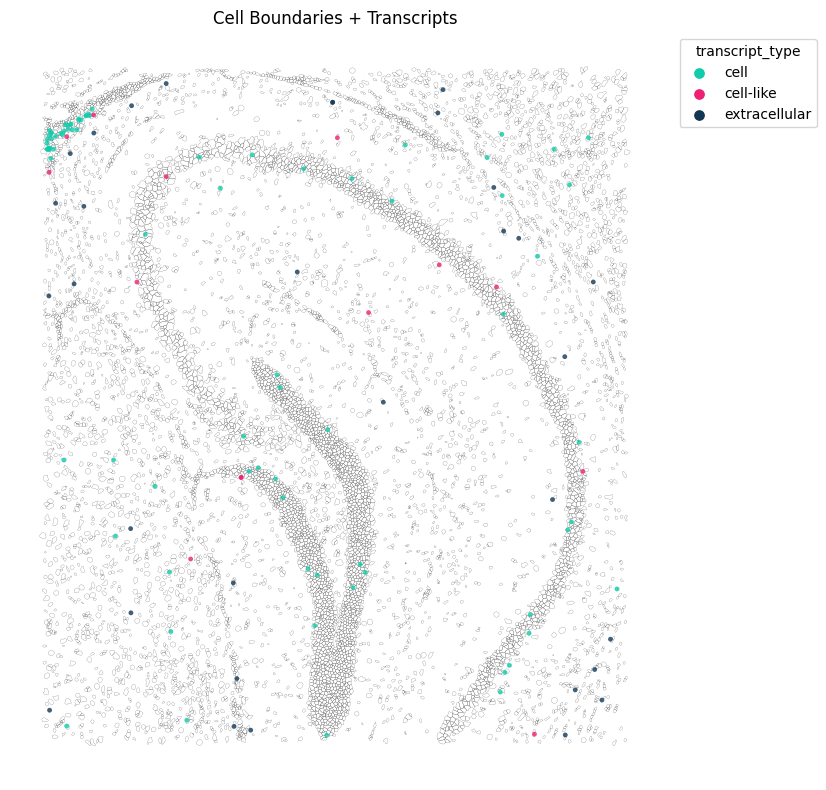

In [294]:
troutpy.pl.spatial_transcripts(sdata,gene_list=['Clic3'],scatter_size=12,boundary_linewidth=0.1)

No transformation matrix found. Proceeding without transformation.


(<Figure size 800x800 with 1 Axes>,
 <Axes: title={'center': 'Cell Boundaries + Transcripts'}>)

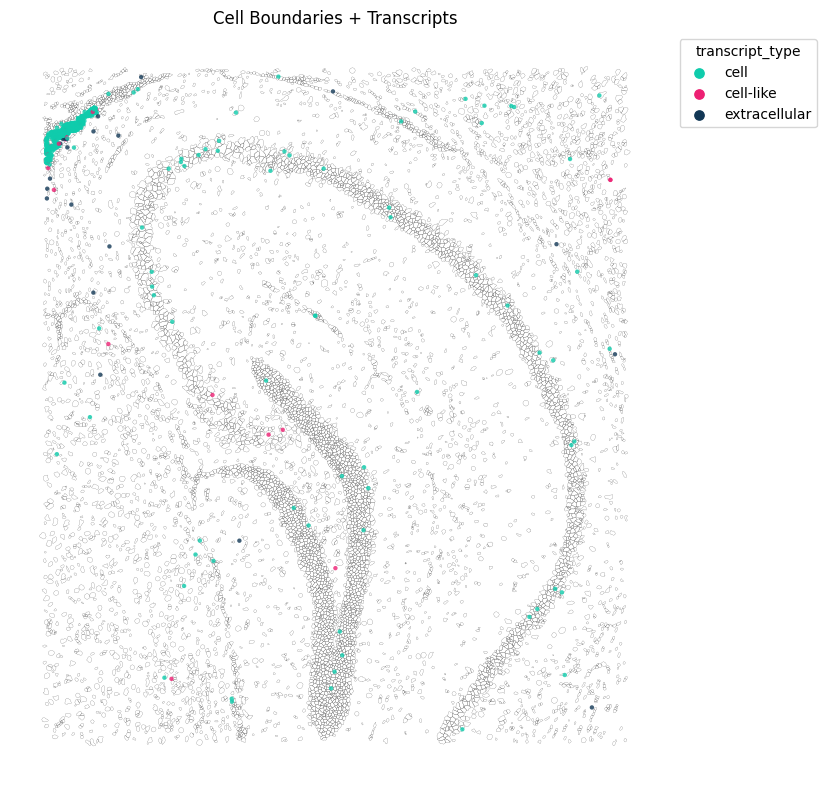

In [295]:
troutpy.pl.spatial_transcripts(sdata,gene_list=['Cldn2'],scatter_size=10,boundary_linewidth=0.1)

No transformation matrix found. Proceeding without transformation.


(<Figure size 800x800 with 1 Axes>,
 <Axes: title={'center': 'Cell Boundaries + Transcripts'}>)

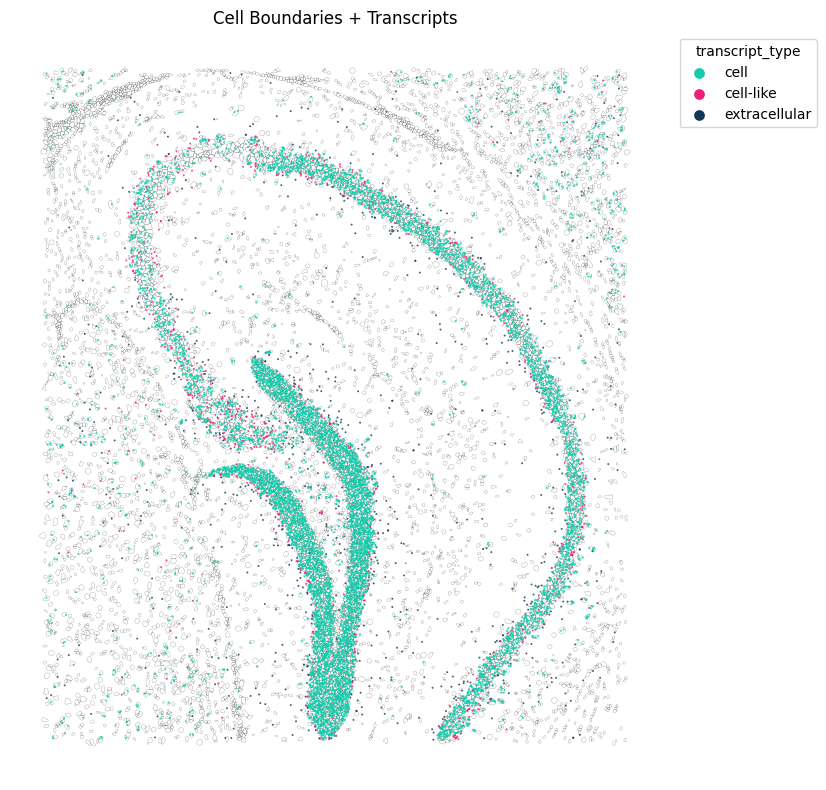

In [189]:
troutpy.pl.spatial_transcripts(sdata,gene_list=['Epha7'],scatter_size=2,boundary_linewidth=0.1)

No transformation matrix found. Proceeding without transformation.


(<Figure size 800x800 with 1 Axes>,
 <Axes: title={'center': 'Cell Boundaries + Transcripts'}>)

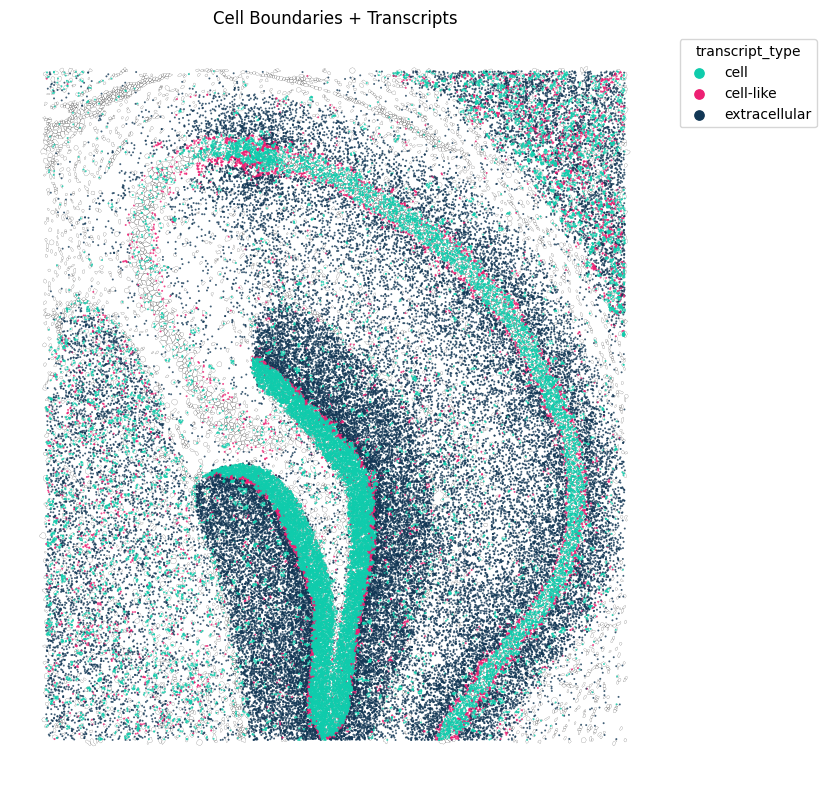

In [190]:
troutpy.pl.spatial_transcripts(sdata,gene_list=['Adcy1'],scatter_size=2,boundary_linewidth=0.1)

No transformation matrix found. Proceeding without transformation.


(<Figure size 800x800 with 1 Axes>,
 <Axes: title={'center': 'Cell Boundaries + Transcripts'}>)

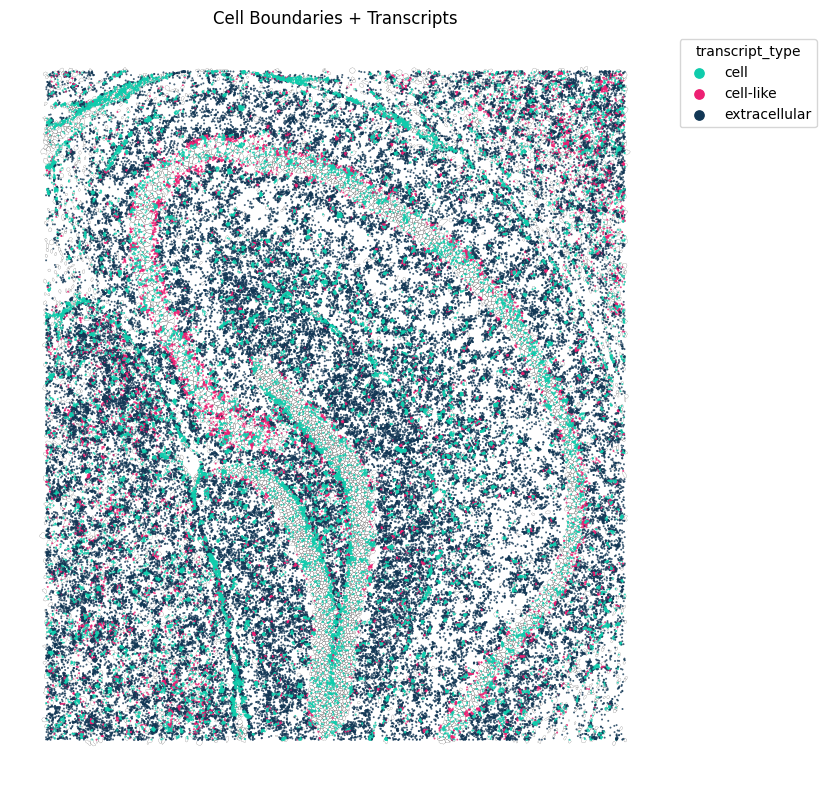

In [183]:
troutpy.pl.spatial_transcripts(sdata,gene_list=['Aldoc'],scatter_size=2,boundary_linewidth=0.1)

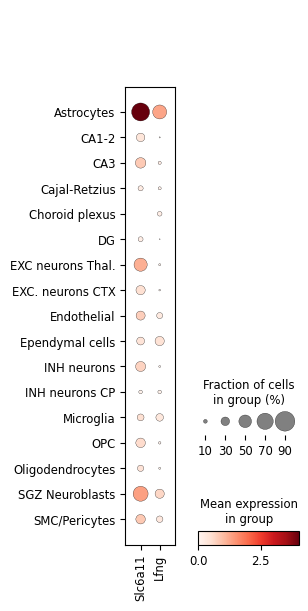

In [260]:
sc.pl.dotplot(adata,['Slc6a11','Lfng'],groupby='cell_type',layer='raw')

No transformation matrix found. Proceeding without transformation.


(<Figure size 800x800 with 1 Axes>,
 <Axes: title={'center': 'Cell Boundaries + Transcripts'}>)

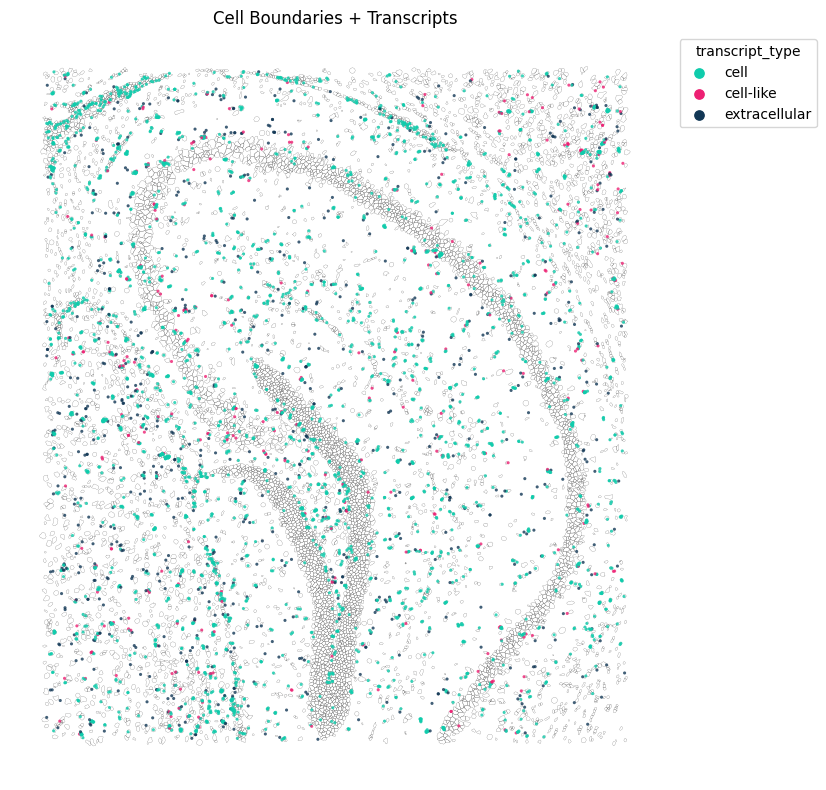

In [184]:
troutpy.pl.spatial_transcripts(sdata,gene_list=['Lfng'],scatter_size=5,boundary_linewidth=0.1)

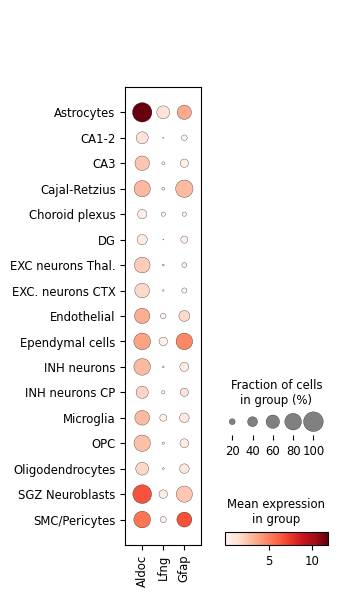

In [188]:
sc.pl.dotplot(adata,['Aldoc','Lfng','Gfap'],groupby='cell_type',layer='raw')

No transformation matrix found. Proceeding without transformation.


(<Figure size 800x800 with 1 Axes>,
 <Axes: title={'center': 'Cell Boundaries + Transcripts'}>)

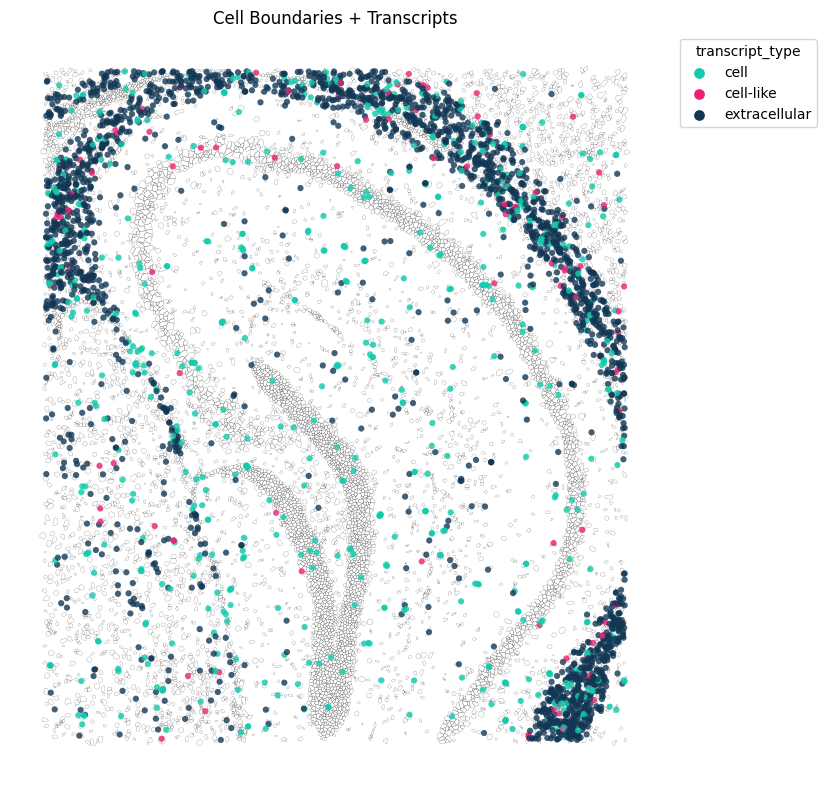

In [27]:
troutpy.pl.spatial_transcripts(sdata,gene_list=['Tmem173'],scatter_size=20,boundary_linewidth=0.1)

No transformation matrix found. Proceeding without transformation.


(<Figure size 800x800 with 1 Axes>,
 <Axes: title={'center': 'Cell Boundaries + Transcripts'}>)

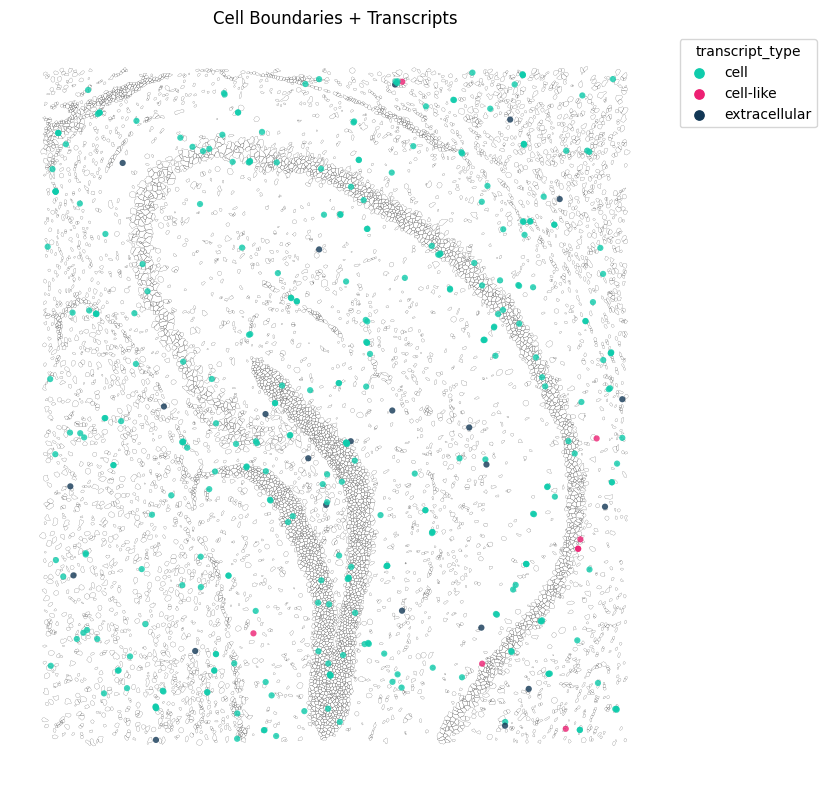

In [28]:
troutpy.pl.spatial_transcripts(sdata,gene_list=['Cd37'],scatter_size=20,boundary_linewidth=0.1)

No transformation matrix found. Proceeding without transformation.


(<Figure size 800x800 with 1 Axes>,
 <Axes: title={'center': 'Cell Boundaries + Transcripts'}>)

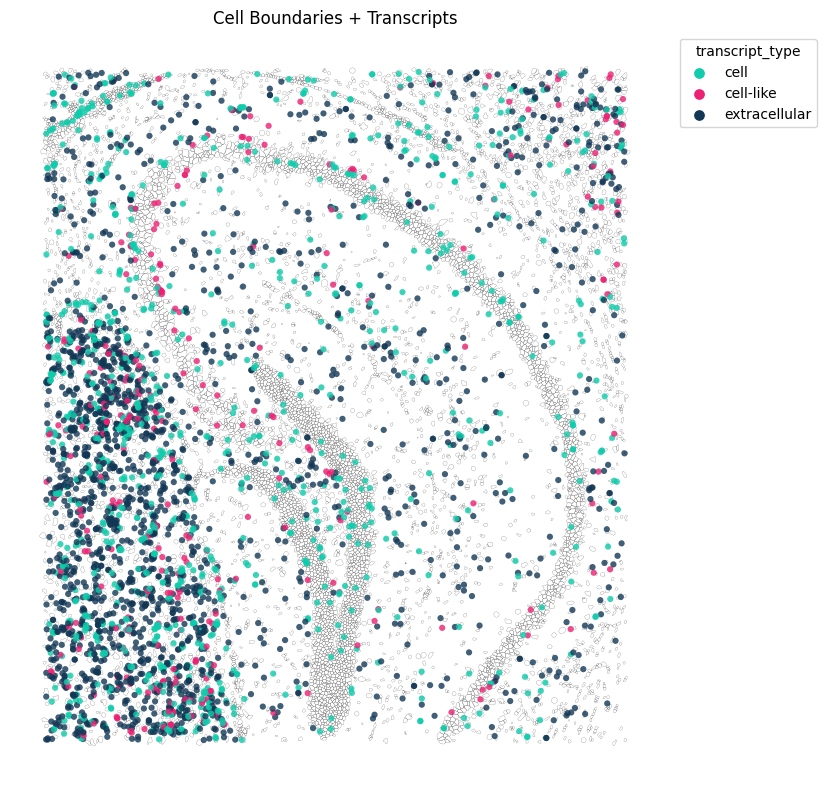

In [29]:
troutpy.pl.spatial_transcripts(sdata,gene_list=['Etnppl'],scatter_size=20,boundary_linewidth=0.1)

No transformation matrix found. Proceeding without transformation.


(<Figure size 800x800 with 1 Axes>,
 <Axes: title={'center': 'Cell Boundaries + Transcripts'}>)

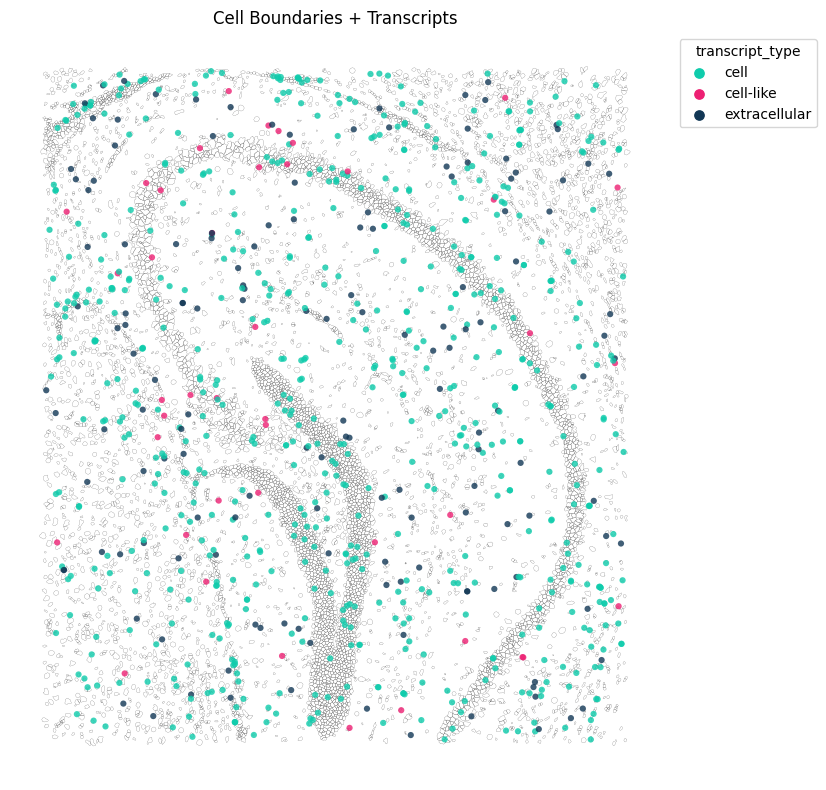

In [30]:
troutpy.pl.spatial_transcripts(sdata,gene_list=['Hif3a'],scatter_size=20,boundary_linewidth=0.1)

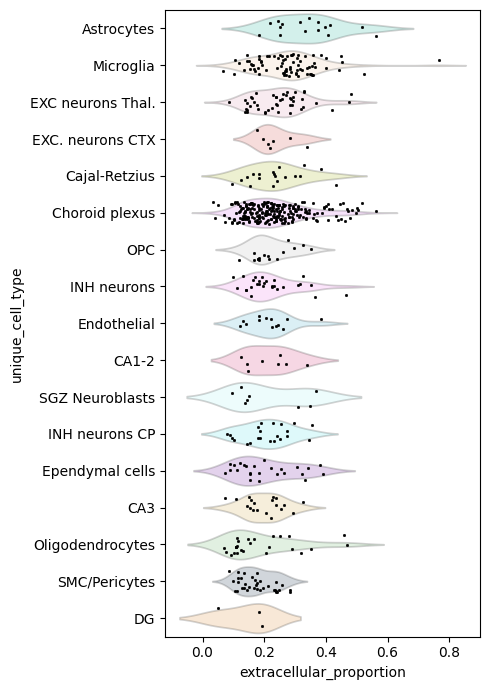

In [24]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

# Parameters
m = 2
n = 2

# Prepare data
merged_labelled = merged.copy()
merged_labelled['gene_name'] = merged_labelled.index

# Create safe order_ct lookup
y_map = {ct: i for i, ct in enumerate(order_ct)}

# Filter to only valid cell types
valid_ct = [ct for ct in merged_labelled['unique_cell_type'].unique() if ct in order_ct]

# Select top and bottom genes
to_label = []
for ct in valid_ct:
    group = merged_labelled[merged_labelled['unique_cell_type'] == ct]
    top_m = group.nlargest(m, 'extracellular_proportion')
    bottom_n = group.nsmallest(n, 'extracellular_proportion')
    to_label.append(pd.concat([top_m, bottom_n]))

label_df = pd.concat(to_label)

# Plot
plt.figure(figsize=(5, 7), dpi=100)

sns.violinplot(
    data=merged_labelled,
    y='unique_cell_type',
    x='extracellular_proportion',
    order=order_ct,
    palette=cols,
    alpha=0.2,
    inner=None
)

sns.stripplot(
    data=merged_labelled,
    y='unique_cell_type',
    x='extracellular_proportion',
    color='black',
    s=2,
    order=order_ct,
    jitter=0.3,
    linewidth=0.2
)

plt.tight_layout()
plt.show()


In [19]:
import matplotlib.pyplot as plt

def plot_scatter_with_labels(group, figsize=(8, 6), label_fontsize=8,title='Gene-level Scatter Plot with Labels'):
    """
    Plot a scatter plot of logfoldratio_over_noise vs. extracellular_proportion
    and annotate each point with the index (e.g., gene name).

    Parameters
    ----------
    group : pd.DataFrame
        DataFrame with 'logfoldratio_over_noise' and 'extracellular_proportion' columns,
        and labels (e.g., gene names) as the index.
    figsize : tuple
        Size of the figure.
    label_fontsize : int
        Font size of the text labels.
    """
    plt.figure(figsize=figsize)
    plt.scatter(group['logfoldratio_over_noise'], group['extracellular_proportion'], s=30, alpha=0.7)
    plt.xlabel('logfoldratio_over_noise')
    plt.ylabel('extracellular_proportion')
    plt.title(title)

    # Add text labels
    for name, row in group.iterrows():
        plt.text(row['logfoldratio_over_noise'], row['extracellular_proportion'], name,
                 fontsize=label_fontsize, ha='right', va='bottom')

    plt.grid(False)
    plt.tight_layout()
    plt.show()


Astrocytes


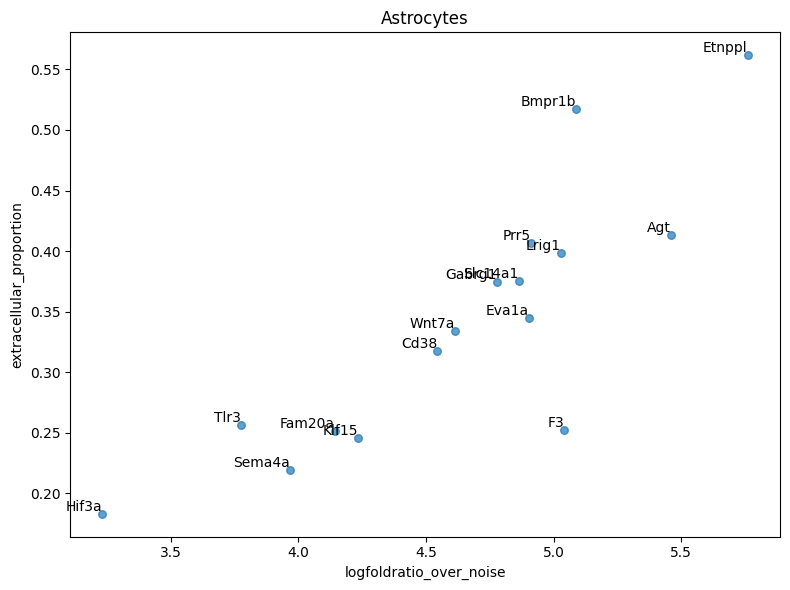

CA1-2


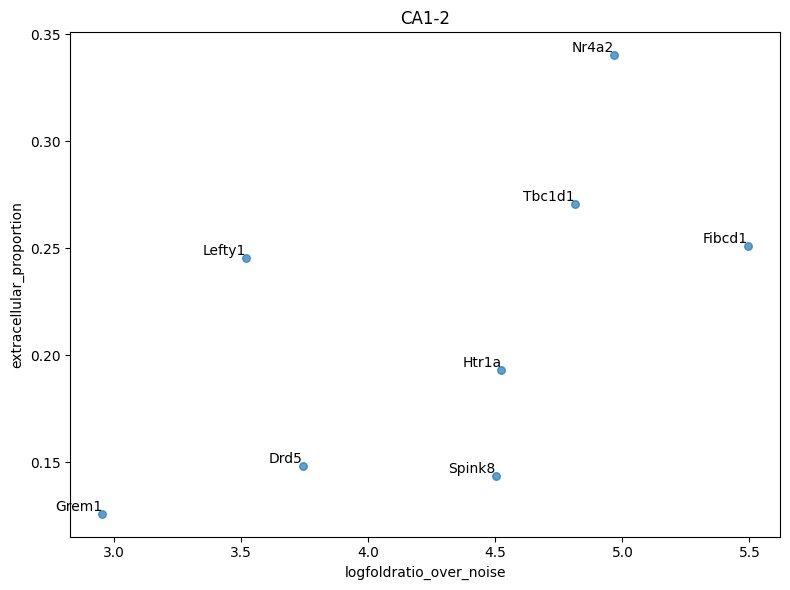

CA3


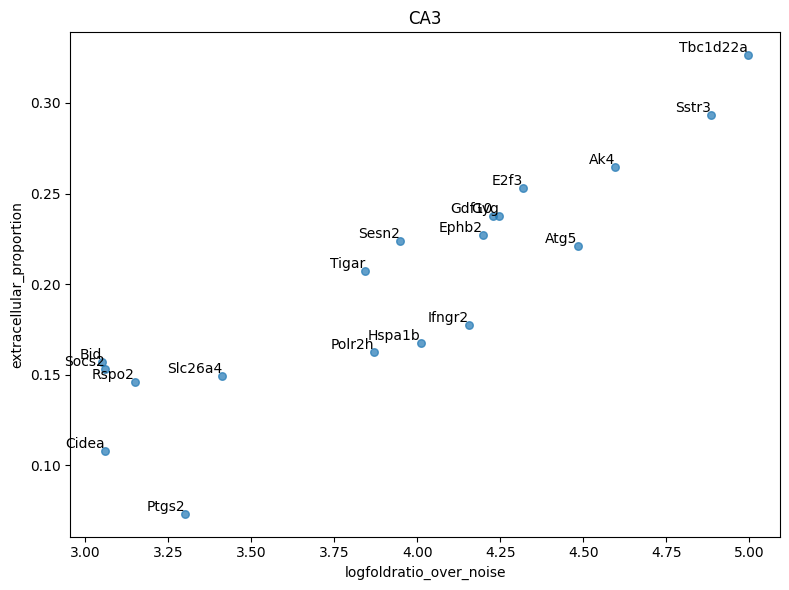

Cajal-Retzius


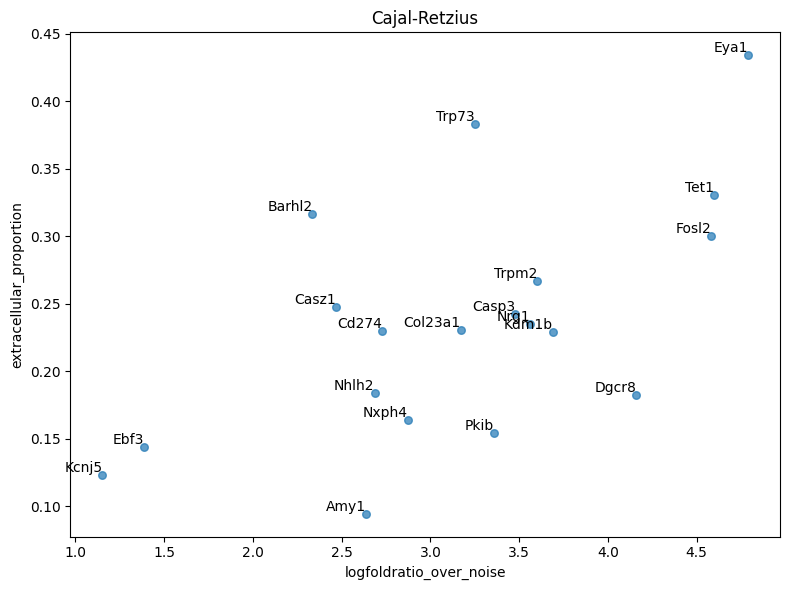

Choroid plexus


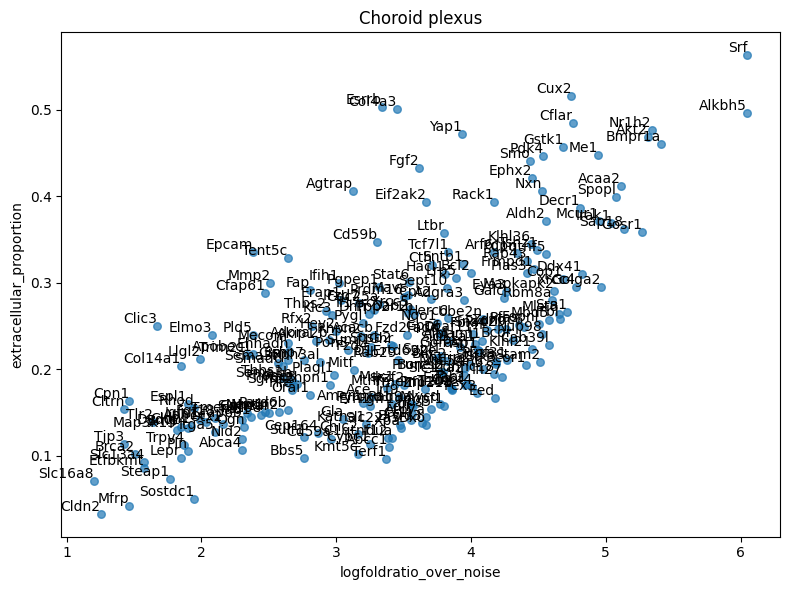

DG


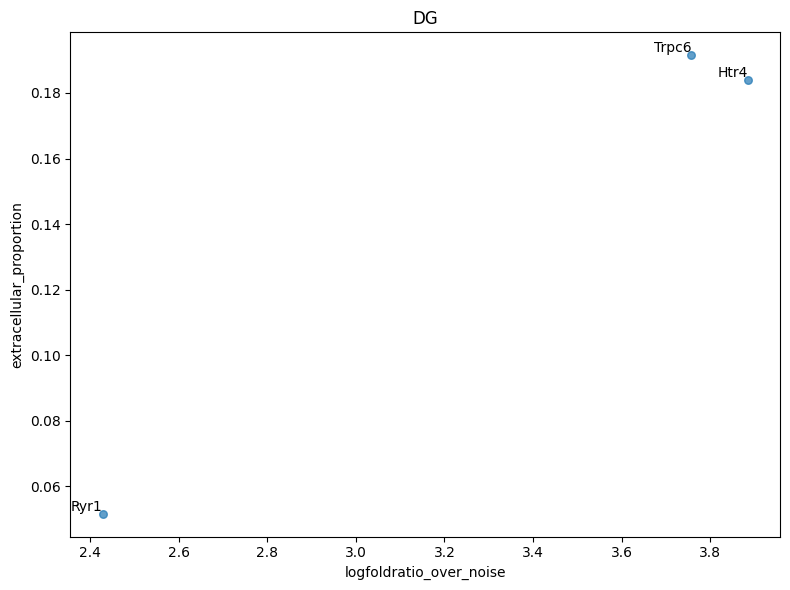

EXC neurons Thal.


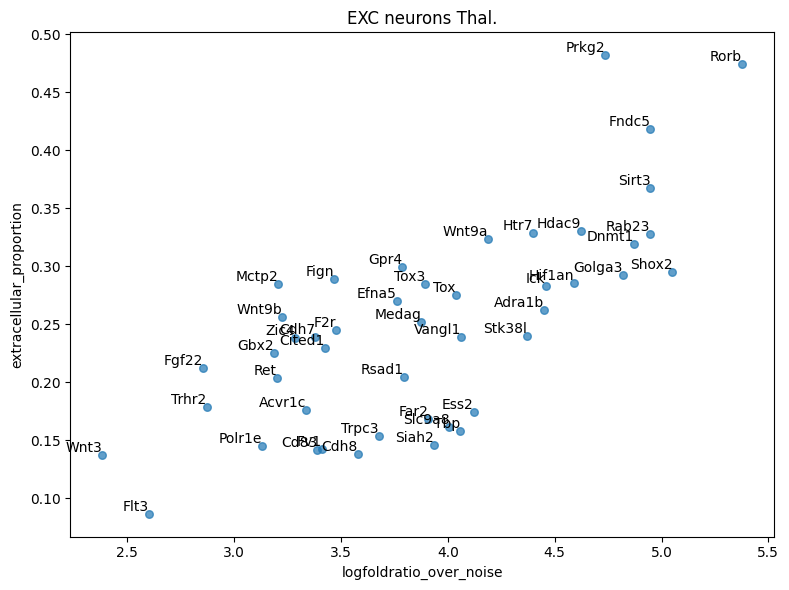

EXC. neurons CTX


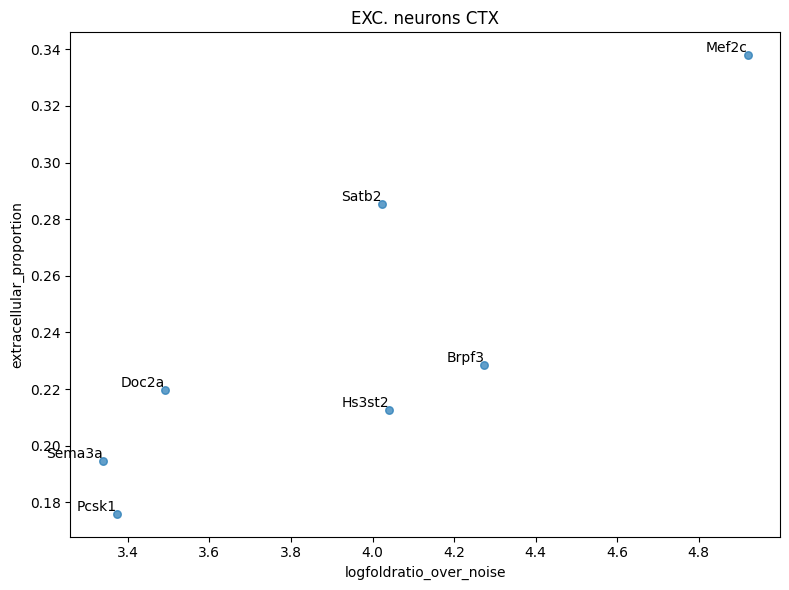

Endothelial


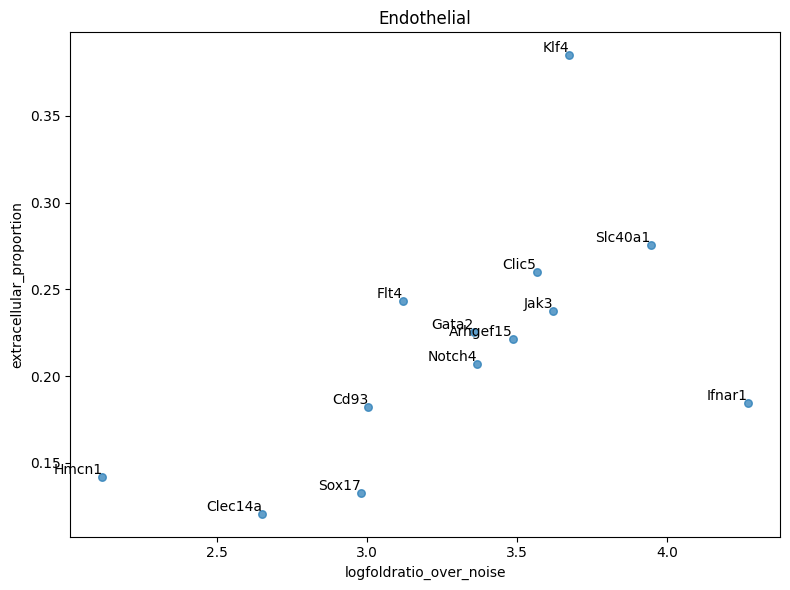

Ependymal cells


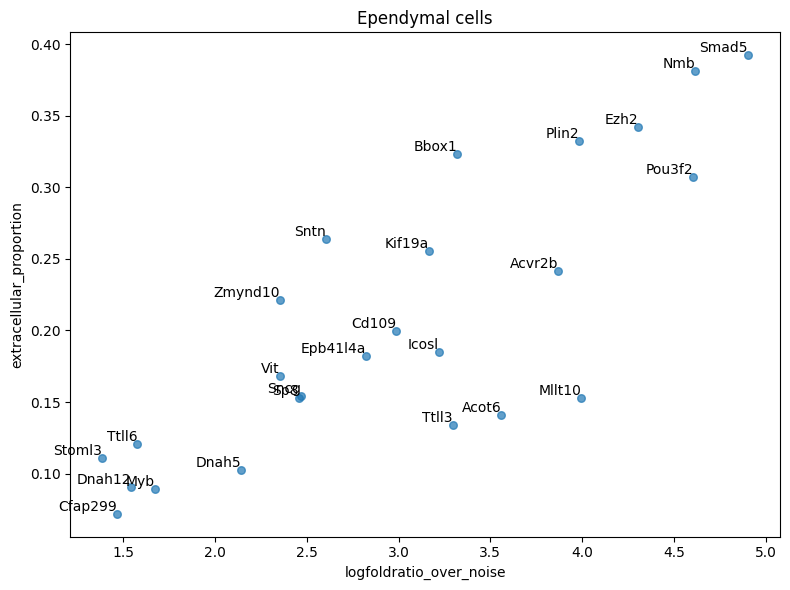

INH neurons


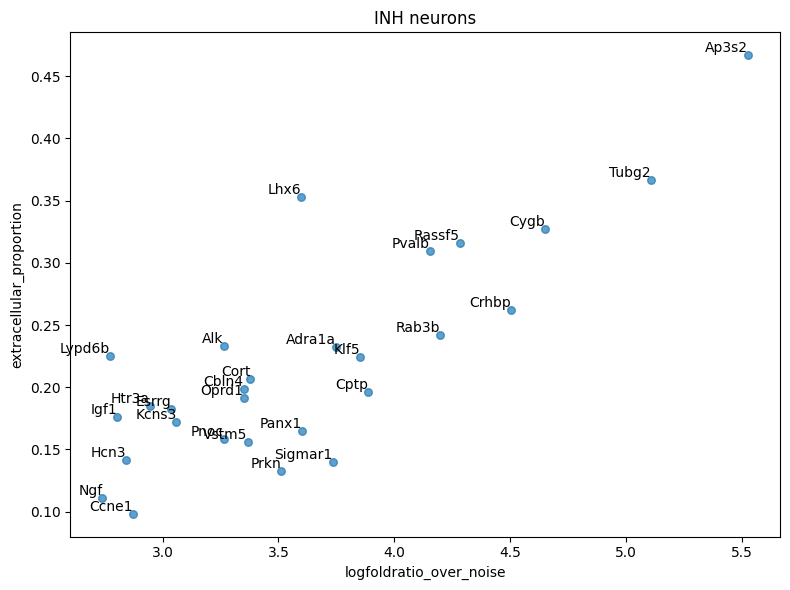

INH neurons CP


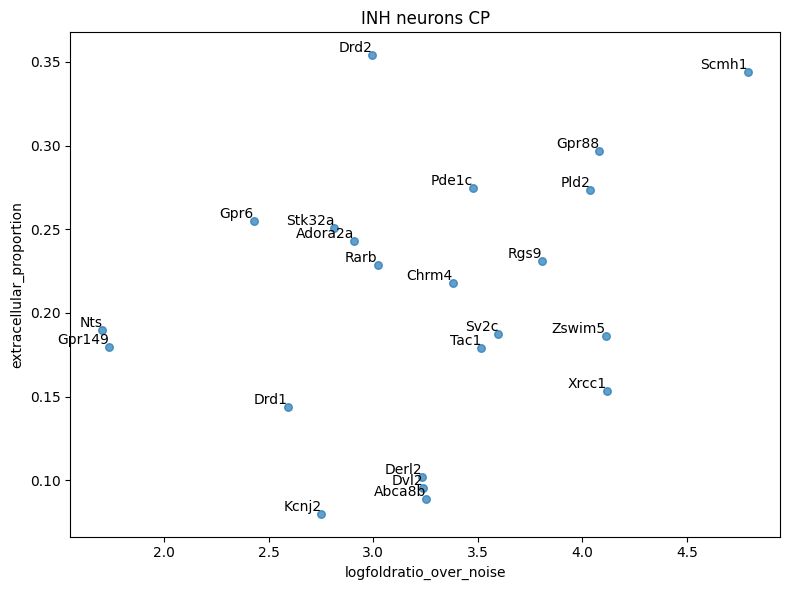

Microglia


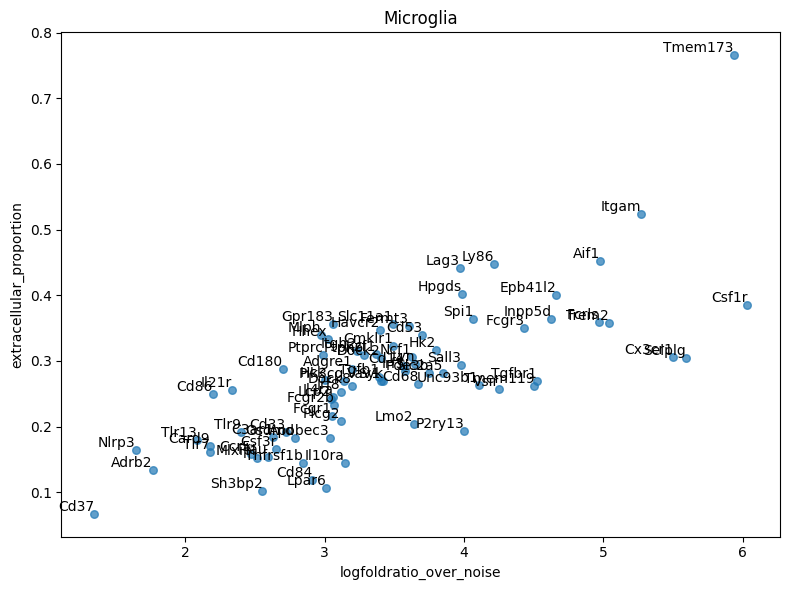

OPC


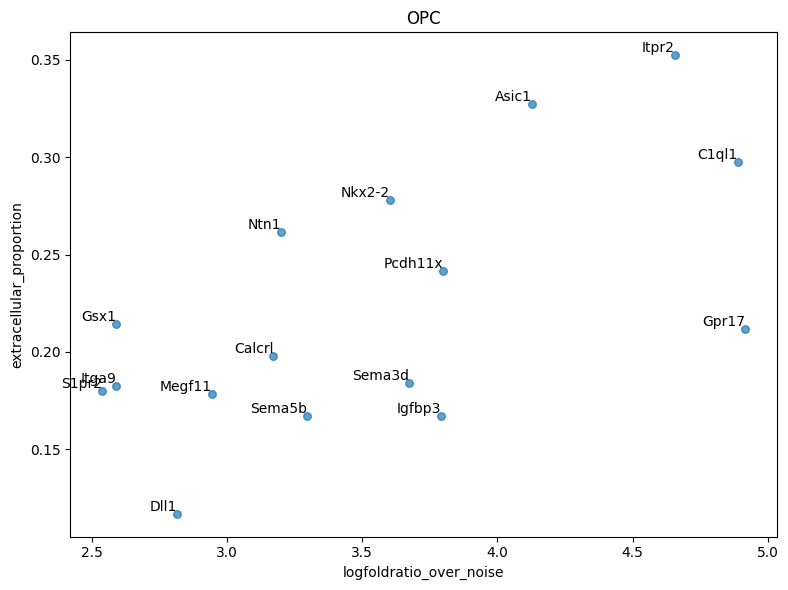

Oligodendrocytes


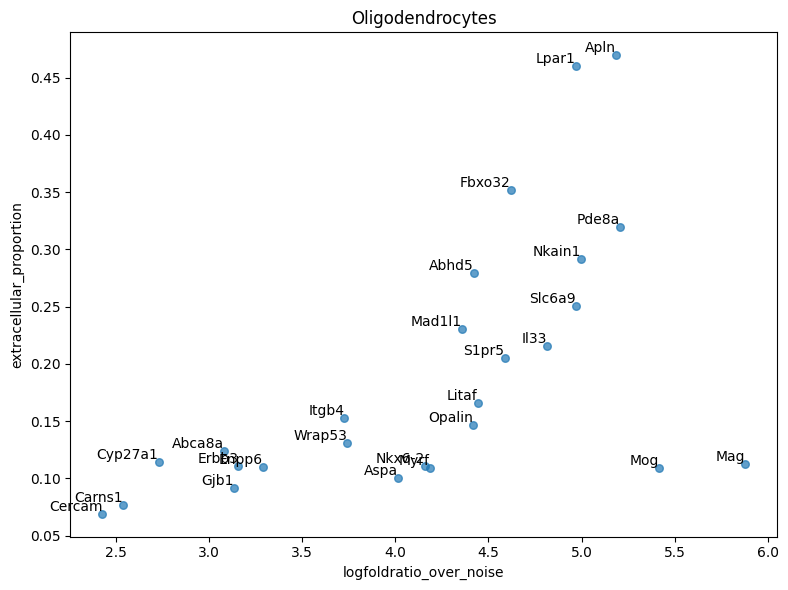

SGZ Neuroblasts


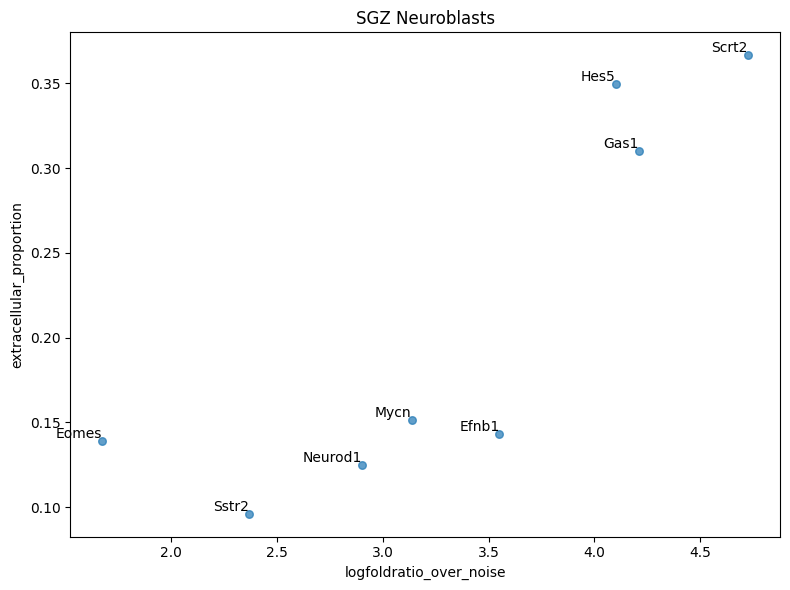

SMC/Pericytes


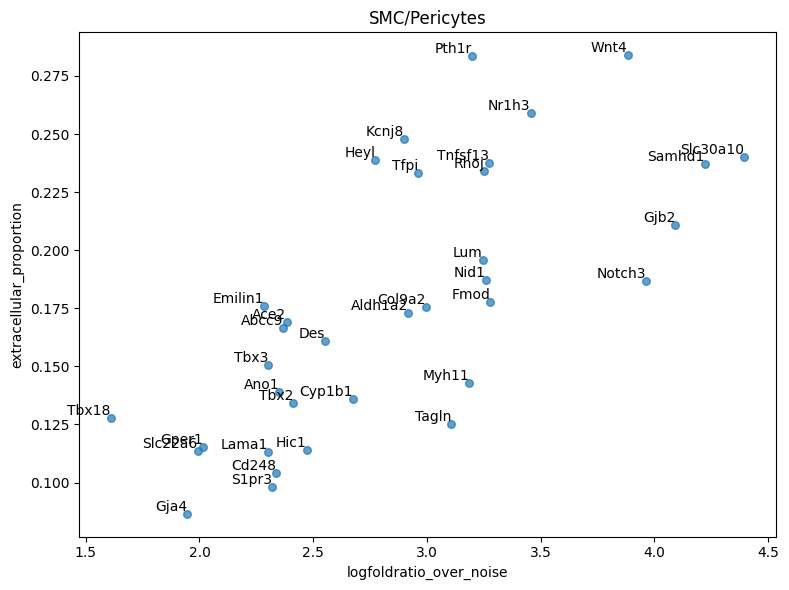

In [21]:
for ct,group in merged.groupby('unique_cell_type'):
    print(ct)
    plot_scatter_with_labels(group, figsize=(8, 6), label_fontsize=10,title=ct)